# The Quantum Hopping Particle

Two-qubit simulation of $H = \Delta X_0 + \tfrac{g}{2} Z_0 Z_1$ with $\Delta = 1$, $\hbar = 1$, time in units of $1/\Delta$.

- $q_0$: position, $|0\rangle = |L\rangle$, $|1\rangle = |R\rangle$. $q_1$: spin, $|0\rangle = |{\uparrow}\rangle$, $|1\rangle = |{\downarrow}\rangle$.
- Initial state $|L\rangle \otimes |+\rangle$.
- Qiskit ordering: Pauli label `"AB"` is A on $q_1$, B on $q_0$; in a counts key the last character is $q_0$.
- **SV** = `Statevector` (exact amplitudes). **Shots** = `StatevectorSampler` with $N$ shots. Every table, legend and caption states which was used.

Run with Restart & Run All (about 1–2 min). Figures go to `figures/`, numerical results to `data/`.

In [1]:
import csv, json, math, time
from itertools import product
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from scipy.linalg import expm
from scipy.optimize import curve_fit
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector, DensityMatrix, Operator, concurrence, partial_trace
from qiskit.primitives import StatevectorSampler

DELTA = 1.0
POS, SPIN = 0, 1
T_MAX, DT_OUT = 10.0, 0.05
G_VALUES = (0.0, 0.5, 1.0, 2.0, 4.0, 8.0)
SHOTS, SEED, SEED_SWEEP = 1000, 1234, 2026
TROTTER_TOL = 1e-3

FIG, DATA = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)
T0 = time.time()
SUMMARY = {"qiskit_version": qiskit.__version__, "numpy_version": np.__version__,
           "seeds": {"validation": SEED, "gradient_sweep": SEED_SWEEP}}

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#dddcd7", "#fcfcfb"
SEQ = {0.0: "#86b6ef", 2.0: "#2a78d6", 8.0: "#104281"}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [C1, "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10, "legend.fontsize": 8.5,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8,
    "figure.facecolor": "white", "axes.facecolor": SURFACE, "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    fig.savefig(FIG / f"{name}.pdf")
    plt.show()


def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    return o


def write_csv(name, header, rows):
    with open(DATA / name, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(header)
        w.writerows(clean(rows))


def write_json(name, obj):
    with open(DATA / name, "w", encoding="utf-8") as f:
        json.dump(clean(obj), f, indent=1)


print(f"qiskit {qiskit.__version__}, numpy {np.__version__}")

qiskit 2.5.2, numpy 2.5.3


In [2]:
def time_grid(t_max=T_MAX, dt=DT_OUT):
    n = int(round(t_max / dt))
    return np.linspace(0.0, n * dt, n + 1)


def hamiltonian(g, delta=DELTA):
    return SparsePauliOp(["IX", "ZZ"], [delta, g / 2])


def initial_circuit():
    qc = QuantumCircuit(2)
    qc.h(SPIN)
    return qc


def initial_state():
    return Statevector(initial_circuit())


def trotter_step_circuit(g, dt, order, delta=DELTA):
    qc = QuantumCircuit(2)
    if order == 1:
        qc.rx(2 * delta * dt, POS)
        qc.rzz(g * dt, POS, SPIN)
    elif order == 2:
        qc.rx(delta * dt, POS)
        qc.rzz(g * dt, POS, SPIN)
        qc.rx(delta * dt, POS)
    else:
        raise ValueError("order must be 1 or 2")
    return qc


def trotter_circuit(g, t, n_steps, order=1, delta=DELTA):
    qc = initial_circuit()
    dt = t / n_steps
    for _ in range(n_steps):
        if order == 1:
            qc.rx(2 * delta * dt, POS)
            qc.rzz(g * dt, POS, SPIN)
        else:
            qc.rx(delta * dt, POS)
            qc.rzz(g * dt, POS, SPIN)
            qc.rx(delta * dt, POS)
    return qc


def exact_circuit(g, t, delta=DELTA):
    omega_ = np.hypot(delta, g / 2)
    theta = np.arctan2(delta, g / 2)
    qc = initial_circuit()
    qc.cx(SPIN, POS)
    qc.ry(-theta, POS)
    qc.rz(2 * omega_ * t, POS)
    qc.ry(theta, POS)
    qc.cx(SPIN, POS)
    return qc


def exact_unitary(g, t, delta=DELTA):
    return expm(-1j * t * hamiltonian(g, delta).to_matrix())


def exact_statevector(g, t, delta=DELTA):
    return initial_state().evolve(Operator(exact_unitary(g, t, delta)))


def exact_trajectory(g, times, delta=DELTA):
    evals, vecs = np.linalg.eigh(hamiltonian(g, delta).to_matrix())
    c0 = vecs.conj().T @ initial_state().data
    return (np.exp(-1j * np.outer(np.asarray(times), evals)) * c0) @ vecs.T


def trotter_unitary(g, t, n_steps, order=1, delta=DELTA):
    u_step = Operator(trotter_step_circuit(g, t / n_steps, order, delta)).data
    return np.linalg.matrix_power(u_step, n_steps)


def trotter_trajectory(g, n_out, dt_out, substeps, order=2, delta=DELTA):
    u_out = np.linalg.matrix_power(
        Operator(trotter_step_circuit(g, dt_out / substeps, order, delta)).data, substeps)
    psi = initial_state().data.copy()
    states = np.empty((n_out + 1, 4), dtype=complex)
    states[0] = psi
    for k in range(1, n_out + 1):
        psi = u_out @ psi
        states[k] = psi
    return dt_out * np.arange(n_out + 1), states


def trotter_error_bound(g, t, n_steps, order, delta=DELTA):
    dt = t / n_steps
    g, delta = abs(g), abs(delta)
    if order == 1:
        return t * dt * delta * g / 2.0
    return t * dt ** 2 * delta * g * (delta + g) / 12.0


def steps_for_tolerance(g, t, tol=TROTTER_TOL, order=2, delta=DELTA):
    g, delta = abs(g), abs(delta)
    if g == 0 or t == 0:
        return 1
    if order == 1:
        n = t ** 2 * delta * g / (2.0 * tol)
    else:
        n = t ** 1.5 * math.sqrt(delta * g * (delta + g) / (12.0 * tol))
    return max(1, math.ceil(n - 1e-9))


def omega(g, delta=DELTA):
    return np.hypot(delta, np.asarray(g, dtype=float) / 2)


def amplitude(g, delta=DELTA):
    return delta ** 2 / omega(g, delta) ** 2


def analytic_PR(g, t, delta=DELTA):
    return amplitude(g, delta) * np.sin(omega(g, delta) * t) ** 2


def analytic_concurrence(g, t, delta=DELTA):
    return abs(g) * delta / omega(g, delta) ** 2 * np.sin(omega(g, delta) * t) ** 2


def _vec(state):
    return state.data if isinstance(state, Statevector) else np.asarray(state)


def p_right(state):
    pr = np.abs(_vec(state)) ** 2
    return float(pr[1] + pr[3])


def p_right_many(states):
    pr = np.abs(np.asarray(states)) ** 2
    return pr[:, 1] + pr[:, 3]


def expval(state, label):
    v = _vec(state)
    return float(np.real(np.vdot(v, SparsePauliOp(label).to_matrix() @ v)))


def expval_many(states, label):
    s = np.asarray(states)
    return np.einsum("ti,ij,tj->t", s.conj(), SparsePauliOp(label).to_matrix(), s).real


def spin_bloch(states):
    return np.stack([expval_many(states, s + "I") for s in "XYZ"], axis=1)


def connected(states, pos, spin):
    return (expval_many(states, spin + pos)
            - expval_many(states, "I" + pos) * expval_many(states, spin + "I"))


def concurrence_many(states):
    s = np.asarray(states)
    return 2.0 * np.abs(s[:, 0] * s[:, 3] - s[:, 1] * s[:, 2])


def infidelity(a, b):
    return float(1.0 - abs(np.vdot(_vec(a), _vec(b))) ** 2)


def infidelity_many(states_a, states_b):
    ov = np.sum(np.conj(np.asarray(states_a)) * np.asarray(states_b), axis=1)
    return 1.0 - np.abs(ov) ** 2


def add_measurement(qc, pos_basis="Z", spin_basis="Z"):
    out = qc.copy()
    for qubit, basis in ((POS, pos_basis), (SPIN, spin_basis)):
        if basis == "X":
            out.h(qubit)
        elif basis == "Y":
            out.sdg(qubit)
            out.h(qubit)
    out.measure_all()
    return out


def sample_counts(circuits, shots=SHOTS, seed=SEED, pos_basis="Z", spin_basis="Z"):
    single = isinstance(circuits, QuantumCircuit)
    circs = [circuits] if single else list(circuits)
    meas = [add_measurement(c, pos_basis, spin_basis) for c in circs]
    res = StatevectorSampler(seed=np.random.default_rng(seed)).run(meas, shots=shots).result()
    counts = [r.data.meas.get_counts() for r in res]
    return counts[0] if single else counts


def bit(key, qubit):
    return int(key[-1 - qubit])


def p_right_from_counts(counts):
    n = sum(counts.values())
    p = sum(c for k, c in counts.items() if bit(k, POS) == 1) / n
    return p, math.sqrt(max(p * (1 - p), 0.0) / n)


def correlator_from_counts(counts, qubits=(POS, SPIN)):
    n = sum(counts.values())
    m = sum(c * (-1) ** sum(bit(k, q) for q in qubits) for k, c in counts.items()) / n
    return m, math.sqrt(max(1 - m * m, 0.0) / n)


def shot_noise(p, shots=SHOTS):
    p = np.asarray(p)
    return np.sqrt(p * (1 - p) / shots)

In [3]:
rng = np.random.default_rng(SEED_SWEEP)
n_checked = 0
for g in (0.0, 0.7, 2.0, 5.0, 16.0):
    ts = rng.uniform(0, 12, 5)
    for t, s in zip(ts, exact_trajectory(g, ts)):
        assert infidelity(exact_statevector(g, t), s) < 1e-10
        assert infidelity(Statevector(exact_circuit(g, t)), s) < 1e-10
        purity = partial_trace(Statevector(s), [POS]).purity().real
        assert abs(math.sqrt(max(0.0, 2 * (1 - purity))) - concurrence_many(s[None])[0]) < 1e-6
        assert abs(p_right(s) - analytic_PR(g, t)) < 1e-10
        n_checked += 1

g, t = 2.0, 1.11
for order in (1, 2):
    full = Operator(trotter_circuit(g, t, 40, order)).data
    fast = trotter_unitary(g, t, 40, order) @ Operator(initial_circuit()).data
    assert np.linalg.norm(full - fast) < 1e-12
    n = steps_for_tolerance(g, t, 1e-4, order)
    assert np.linalg.norm(trotter_unitary(g, t, n, order) - exact_unitary(g, t), 2) <= 1e-4
tt, st = trotter_trajectory(g, 20, 0.1, 3, 2)
assert infidelity(st[-1], Statevector(trotter_circuit(g, tt[-1], 60, 2))) < 1e-12
assert all(bit(k, POS) == 1 for k in sample_counts(trotter_circuit(0.0, math.pi / 2, 1, 1), shots=2000))
print(f"consistency checks passed ({n_checked} random (g, t) points + Trotter/sampler checks)")

consistency checks passed (25 random (g, t) points + Trotter/sampler checks)


## 1. Model and circuits

| Term | Gate | Angle |
|---|---|---|
| $\Delta X_0$ | `RX` on $q_0$ | $2\Delta\,dt$ |
| $\tfrac g2 Z_0Z_1$ | `RZZ` on $(q_0, q_1)$ | $g\,dt$ |
| $\lvert L\rangle\otimes\lvert+\rangle$ | `H` on $q_1$ | |
| measurement | none / `H` / `S†H` on the measured qubit, then `measure_all` | |

Trotter-1: $e^{-iB\,dt}e^{-iA\,dt}$. Trotter-2: $e^{-iA\,dt/2}e^{-iB\,dt}e^{-iA\,dt/2}$, with $A = \Delta X_0$, $B = \tfrac g2 Z_0Z_1$.
Step counts come from the commutator bounds $\|U_1^n - e^{-iHt}\| \le \tfrac{t\,dt}{2}\Delta g$ and $\|U_2^n - e^{-iHt}\| \le \tfrac{t\,dt^2}{12}\Delta g(\Delta+g)$, with tolerance $10^{-3}$.
Reference: exact circuit $CX\cdot R_{\hat n}(2\Omega t)\cdot CX$ and `scipy.linalg.expm`.

In [4]:
print("Trotter-1 step")
print(trotter_step_circuit(2.0, 0.1, 1).draw("text"))
print("Trotter-2 step")
print(trotter_step_circuit(2.0, 0.1, 2).draw("text"))
print("Exact circuit, g = 2, t = 1")
print(exact_circuit(2.0, 1.0).draw("text"))

A_op = SparsePauliOp("IX", DELTA)
B_op = SparsePauliOp("ZZ", 2.0 / 2)
comm = lambda P, Q: (P.dot(Q) - Q.dot(P)).simplify()
print("[A,B]     =", comm(A_op, B_op).to_list())
print("[A,[A,B]] =", comm(A_op, comm(A_op, B_op)).to_list())
print("[B,[B,A]] =", comm(B_op, comm(B_op, A_op)).to_list())

basis = ["cx", "rz", "sx", "x"]
cx_step = {o: transpile(trotter_step_circuit(2.0, 0.1, o), basis_gates=basis,
                        optimization_level=1).count_ops().get("cx", 0) for o in (1, 2)}
cx_exact = transpile(exact_circuit(2.0, 10.0), basis_gates=basis,
                     optimization_level=1).count_ops().get("cx", 0)
cost = []
print(f"\nCX count to reach t = {T_MAX:g} with ||error|| <= {TROTTER_TOL:g}")
print(f"{'g':>4} {'exact':>6} {'n T2':>7} {'CX T2':>7} {'n T1':>8} {'CX T1':>9}")
for g in (0.5, 2.0, 8.0):
    n2 = steps_for_tolerance(g, T_MAX, TROTTER_TOL, 2)
    n1 = steps_for_tolerance(g, T_MAX, TROTTER_TOL, 1)
    cost.append(dict(g=g, cx_exact=cx_exact, n2=n2, cx2=n2 * cx_step[2], n1=n1, cx1=n1 * cx_step[1]))
    print(f"{g:4.1f} {cx_exact:6d} {n2:7d} {n2 * cx_step[2]:7d} {n1:8d} {n1 * cx_step[1]:9d}")
SUMMARY["circuit_cost"] = dict(cx_per_step=cx_step, cx_exact=cx_exact, table=cost)

Trotter-1 step
     ┌─────────┐          
q_0: ┤ Rx(0.2) ├─■────────
     └─────────┘ │ZZ(0.2) 
q_1: ────────────■────────
                          
Trotter-2 step
     ┌─────────┐          ┌─────────┐
q_0: ┤ Rx(0.1) ├─■────────┤ Rx(0.1) ├
     └─────────┘ │ZZ(0.2) └─────────┘
q_1: ────────────■───────────────────
                                     
Exact circuit, g = 2, t = 1
          ┌───┐┌──────────┐┌────────────┐┌─────────┐┌───┐
q_0: ─────┤ X ├┤ Ry(-π/4) ├┤ Rz(2.8284) ├┤ Ry(π/4) ├┤ X ├
     ┌───┐└─┬─┘└──────────┘└────────────┘└─────────┘└─┬─┘
q_1: ┤ H ├──■─────────────────────────────────────────■──
     └───┘                                               
[A,B]     = [('ZY', -2j)]
[A,[A,B]] = [('ZZ', (4+0j))]
[B,[B,A]] = [('IX', (4+0j))]



CX count to reach t = 10 with ||error|| <= 0.001
   g  exact    n T2   CX T2     n T1     CX T1
 0.5      2     250     500    25000     50000
 2.0      2     708    1416   100000    200000
 8.0      2    2450    4900   400000    800000


## 2. Validation at test points

Each method against the analytic $P_R$ and `expm`. Shots: Trotter-2 circuit, $N = 10^4$, $z = (\hat p - p)/\sqrt{p(1-p)/N}$.

In [5]:
test_points = [(0.0, math.pi / 2), (1.0, 3.0), (2.0, math.pi / (2 * math.sqrt(2))), (4.0, 2.0), (8.0, T_MAX)]
N_VAL = 10_000
rows = []
for i, (g, t) in enumerate(test_points):
    ref = exact_statevector(g, t)
    sv_exact = Statevector.from_instruction(exact_circuit(g, t))
    n2 = steps_for_tolerance(g, t, TROTTER_TOL, 2)
    qc2 = trotter_circuit(g, t, n2, 2)
    sv_t2 = Statevector.from_instruction(qc2)
    n1 = steps_for_tolerance(g, t, TROTTER_TOL, 1)
    sv_t1 = Statevector(trotter_unitary(g, t, n1, 1) @ initial_state().data)
    p_shot, _ = p_right_from_counts(sample_counts(qc2, shots=N_VAL, seed=SEED + i))
    p_an = float(analytic_PR(g, t))
    sig = float(shot_noise(p_an, N_VAL))
    rows.append(dict(g=g, t=round(t, 4), P_analytic=p_an, P_expm=p_right(ref),
                     P_exact_circuit=p_right(sv_exact), P_trotter2=p_right(sv_t2), n2=n2,
                     P_trotter1=p_right(sv_t1), n1=n1, P_shots=p_shot, sigma=sig,
                     z=(p_shot - p_an) / sig if sig > 1e-12 else float("nan"),
                     infid_exact_circuit=infidelity(sv_exact, ref),
                     infid_trotter2=infidelity(sv_t2, ref), infid_trotter1=infidelity(sv_t1, ref)))

hdr = (f"{'g':>4} {'t':>6} | {'analytic':>8} {'expm':>8} {'exact SV':>8} {'T2 SV':>8} {'n':>6} "
       f"{'T1 SV':>8} {'n':>7} | {'shots':>7} {'z':>6}")
print(hdr)
print("-" * len(hdr))
for r in rows:
    z = "exact" if math.isnan(r["z"]) else f"{r['z']:+.2f}"
    print(f"{r['g']:4.1f} {r['t']:6.3f} | {r['P_analytic']:8.5f} {r['P_expm']:8.5f} {r['P_exact_circuit']:8.5f} "
          f"{r['P_trotter2']:8.5f} {r['n2']:6d} {r['P_trotter1']:8.5f} {r['n1']:7d} | {r['P_shots']:7.4f} {z:>6}")

dev = {k: max(abs(r[k] - r["P_analytic"]) for r in rows)
       for k in ("P_expm", "P_exact_circuit", "P_trotter2", "P_trotter1")}
max_inf_exact = max(r["infid_exact_circuit"] for r in rows)
zs = [r["z"] for r in rows if not math.isnan(r["z"])]
print(f"\nmax |P - analytic|: expm {dev['P_expm']:.1e}, exact circuit {dev['P_exact_circuit']:.1e}, "
      f"Trotter-2 {dev['P_trotter2']:.1e}, Trotter-1 {dev['P_trotter1']:.1e}")
print(f"max infidelity, exact circuit vs expm: {max_inf_exact:.1e};  shots: max |z| = {max(map(abs, zs)):.2f}")
assert dev["P_exact_circuit"] < 1e-12 and dev["P_expm"] < 1e-12
assert dev["P_trotter2"] < 2e-3 and dev["P_trotter1"] < 2e-3
assert rows[0]["P_shots"] == 1.0 and max(map(abs, zs)) < 4
SUMMARY["validation"] = dict(rows=rows, max_dev=dev, max_infid_exact=max_inf_exact,
                             max_abs_z=max(map(abs, zs)), shots=N_VAL)
write_csv("validation_points.csv", list(rows[0]), [list(r.values()) for r in rows])

   g      t | analytic     expm exact SV    T2 SV      n    T1 SV       n |   shots      z
------------------------------------------------------------------------------------------
 0.0  1.571 |  1.00000  1.00000  1.00000  1.00000      1  1.00000       1 |  1.0000  exact
 1.0  3.000 |  0.03559  0.03559  0.03559  0.03551     68  0.03559    4500 |  0.0331  -1.34
 2.0  1.111 |  0.50000  0.50000  0.50000  0.49958     27  0.50000    1234 |  0.4945  -1.10
 4.0  2.000 |  0.18868  0.18868  0.18868  0.18853    116  0.18868    8000 |  0.1933  +1.18
 8.0 10.000 |  0.00852  0.00852  0.00852  0.00851   2450  0.00852  400000 |  0.0101  +1.72

max |P - analytic|: expm 2.2e-16, exact circuit 2.2e-16, Trotter-2 4.2e-04, Trotter-1 2.0e-07
max infidelity, exact circuit vs expm: 8.9e-16;  shots: max |z| = 1.72


## 3. Baseline, $g = 0$ (F1)

Only the tunnelling term remains, so Trotter is exact here and $P_R = \sin^2(\Delta t)$.

SV vs sin^2(t): max |error| = 4.7e-14
shot fit: A = 0.992 +/- 0.006, Omega = 0.9997 +/- 0.0008, period = 3.142 +/- 0.003
spin at g = 0: max |Bloch - (1,0,0)| = 5.9e-14, max concurrence = 0.0e+00
shots (N = 1000) vs sin^2(t): chi2/dof = 1.48 over 20 points, 90% within 2 sigma
<Z1>: SV max 5.6e-17;  shots chi2/dof vs 0 = 0.88 (g = 0), 0.85 (g = 2)


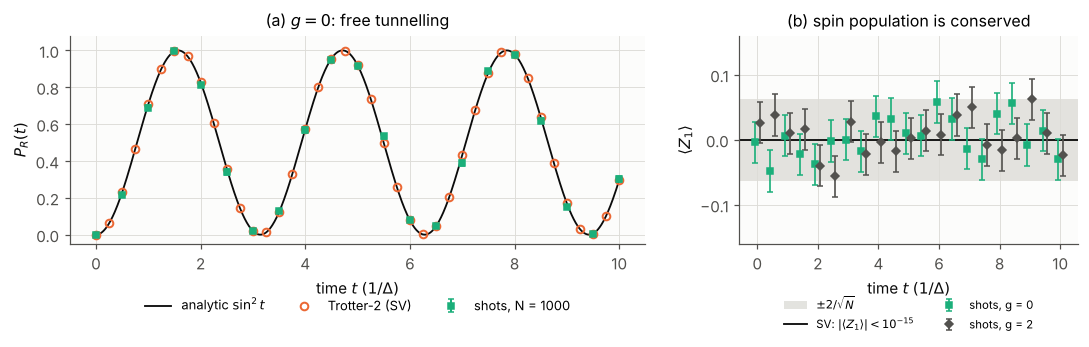

In [6]:
N = SHOTS
times = time_grid()
_, st0 = trotter_trajectory(0.0, len(times) - 1, DT_OUT, 1, order=2)
p_sv0 = p_right_many(st0)
f1_sv_err = float(np.max(np.abs(p_sv0 - np.sin(times) ** 2)))
assert f1_sv_err < 1e-10

t_shot = np.round(np.arange(0.0, T_MAX + 1e-9, 0.5), 10)


def prod_circuit(g, t):
    return trotter_circuit(g, t, steps_for_tolerance(g, t, TROTTER_TOL, 2), 2)


counts = {0.0: sample_counts([prod_circuit(0.0, t) for t in t_shot], shots=N, seed=SEED),
          2.0: sample_counts([prod_circuit(2.0, t) for t in t_shot], shots=N, seed=SEED + 1)}
p_sh = np.array([p_right_from_counts(c)[0] for c in counts[0.0]])
p_true = np.sin(t_shot) ** 2
sig = shot_noise(p_true, N)
m = sig > 1e-9
f1_chi2 = float(np.mean(((p_sh - p_true)[m] / sig[m]) ** 2))
f1_within2 = float(np.mean(np.abs(p_sh - p_true)[m] <= 2 * sig[m]))
assert np.all(p_sh[~m] == np.round(p_true[~m]))

z1 = {g: np.array([correlator_from_counts(c, (SPIN,)) for c in counts[g]]) for g in counts}
z1_chi2 = {g: float(np.mean((z1[g][:, 0] * math.sqrt(N)) ** 2)) for g in z1}
_, st2 = trotter_trajectory(2.0, len(times) - 1, DT_OUT,
                            math.ceil(steps_for_tolerance(2.0, T_MAX, TROTTER_TOL, 2) / (len(times) - 1)), 2)
z1_sv = max(float(np.max(np.abs(expval_many(s, "ZI")))) for s in (st0, st2))

(pA, pW), cov = curve_fit(lambda t, A, W: A * np.sin(W * t) ** 2, t_shot, p_sh, p0=[0.9, 0.9])
eA, eW = np.sqrt(np.diag(cov))
period, e_period = math.pi / pW, math.pi * eW / pW ** 2
b0 = spin_bloch(st0)
spin_dev = float(np.max(np.abs(b0 - np.array([1.0, 0.0, 0.0]))))
c0_max = float(concurrence_many(st0).max())

print(f"SV vs sin^2(t): max |error| = {f1_sv_err:.1e}")
print(f"shot fit: A = {pA:.3f} +/- {eA:.3f}, Omega = {pW:.4f} +/- {eW:.4f}, period = {period:.3f} +/- {e_period:.3f}")
print(f"spin at g = 0: max |Bloch - (1,0,0)| = {spin_dev:.1e}, max concurrence = {c0_max:.1e}")
print(f"shots (N = {N}) vs sin^2(t): chi2/dof = {f1_chi2:.2f} over {m.sum()} points, {100 * f1_within2:.0f}% within 2 sigma")
print(f"<Z1>: SV max {z1_sv:.1e};  shots chi2/dof vs 0 = {z1_chi2[0.0]:.2f} (g = 0), {z1_chi2[2.0]:.2f} (g = 2)")
SUMMARY["baseline_g0"] = dict(sv_max_err=f1_sv_err, shots=N, n_shot_points=int(m.sum()), chi2=f1_chi2,
                              fit_A=pA, fit_A_err=eA, fit_Omega=pW, fit_Omega_err=eW, period=period,
                              period_err=e_period, spin_dev=spin_dev, concurrence_max=c0_max,
                              within_2sigma=f1_within2, z1_sv_max=z1_sv, z1_chi2=z1_chi2)
write_csv("baseline_g0_shots.csv",
          ["t", "P_R_shots", "P_R_err", "P_R_exact", "Z1_g0", "Z1_g0_err", "Z1_g2", "Z1_g2_err"],
          [[t, p, e, q, a[0], a[1], b[0], b[1]] for t, p, e, q, a, b in
           zip(t_shot, p_sh, shot_noise(p_sh, N), p_true, z1[0.0], z1[2.0])])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.7, 1]})
tt = np.linspace(0, T_MAX, 1000)
ax1.plot(tt, np.sin(tt) ** 2, color=INK, lw=1.2, label=r"analytic $\sin^2 t$")
ax1.plot(times[::5], p_sv0[::5], "o", ms=5, mfc="none", mec=C2, mew=1.3, label="Trotter-2 (SV)")
ax1.errorbar(t_shot, p_sh, yerr=shot_noise(p_sh, N), fmt="s", ms=4.5, color=C3, ecolor=C3,
             elinewidth=1.3, capsize=2, label=f"shots, N = {N}")
ax1.set(xlabel=r"time $t$ $(1/\Delta)$", ylabel=r"$P_R(t)$", ylim=(-0.05, 1.08), title=r"(a) $g = 0$: free tunnelling")
ax1.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.2))
band = 2 / math.sqrt(N)
ax2.axhspan(-band, band, color=GRID, alpha=0.8, lw=0, label=r"$\pm 2/\sqrt{N}$")
ax2.axhline(0, color=INK, lw=1.2, label=r"SV: $|\langle Z_1\rangle| < 10^{-15}$")
for g, mk, dx in ((0.0, "s", -0.08), (2.0, "D", 0.08)):
    ax2.errorbar(t_shot + dx, z1[g][:, 0], yerr=z1[g][:, 1], fmt=mk, ms=4, color=C3 if g == 0 else INK2,
                 elinewidth=1.1, capsize=2, label=f"shots, g = {g:g}")
ax2.set(xlabel=r"time $t$ $(1/\Delta)$", ylabel=r"$\langle Z_1\rangle$", ylim=(-0.16, 0.16),
        title="(b) spin population is conserved")
ax2.legend(loc="upper center", fontsize=7.5, ncol=2, bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
save(fig, "F1_baseline_g0")

## 4. Measurement and sampling checks

The position bit is the last character of a counts key. `StatevectorSampler(seed=<int>)` gives every circuit in a job the same random draws, so all shot data here are seeded with a `numpy.random.Generator`.

In [7]:
c = sample_counts(trotter_circuit(0.0, math.pi / 2, 1, 2), shots=1000, seed=SEED)
print("g = 0, t = pi/2 counts:", c)
print("P_R from last character :", p_right_from_counts(c)[0])
print("P_R from first character:", sum(v for k, v in c.items() if k[0] == "1") / 1000)
p, se = p_right_from_counts(sample_counts(trotter_circuit(0.0, math.pi / 4, 1, 2), shots=1000, seed=SEED))
print(f"g = 0, t = pi/4: P_R = {p:.3f} +/- {se:.3f}")
for basis in ("X", "Y"):
    c = sample_counts(trotter_circuit(0.0, 0.7, 1, 2), shots=4000, seed=SEED, spin_basis=basis)
    v, e = correlator_from_counts(c, (SPIN,))
    print(f"<{basis}1> at g = 0: {v:+.3f} +/- {e:.3f}")

circs = [add_measurement(trotter_circuit(0.0, 0.5 * k, 1, 2)) for k in range(5)]
int_seed = [sum(v for k, v in r.data.meas.get_counts().items() if bit(k, SPIN) == 0)
            for r in StatevectorSampler(seed=SEED).run(circs, shots=1000).result()]
gen_seed = [sum(v for k, v in cnt.items() if bit(k, SPIN) == 0)
            for cnt in sample_counts([trotter_circuit(0.0, 0.5 * k, 1, 2) for k in range(5)], shots=1000)]
print("spin-up counts over 5 circuits, integer seed  :", int_seed)
print("spin-up counts over 5 circuits, Generator seed:", gen_seed)
SUMMARY["seed_check"] = dict(int_seed=int_seed, generator_seed=gen_seed)

g = 0, t = pi/2 counts: {'11': 502, '01': 498}
P_R from last character : 1.0
P_R from first character: 0.502
g = 0, t = pi/4: P_R = 0.486 +/- 0.016
<X1> at g = 0: +1.000 +/- 0.000
<Y1> at g = 0: -0.017 +/- 0.016
spin-up counts over 5 circuits, integer seed  : [498, 498, 498, 498, 498]
spin-up counts over 5 circuits, Generator seed: [498, 476, 503, 489, 481]


## 5. Effect of the field gradient (F2, F3)

Fits of $P_R(t) = A\sin^2(\Omega t)$: scan $\Omega$ on a log grid with $A$ solved linearly, then refine with `curve_fit`. Shot fits weight each point by the binomial variance of the model probability. Model-free check: $2\langle P_R\rangle_t$ over $t \in [0, 400\pi]$.

In [8]:
TS = np.linspace(0, 4 * np.pi, 4001)
T_LONG = np.linspace(0, 400 * np.pi, 200001)
G_SWEEP = [0.0, 0.125, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0, 32.0]

series = {}
for g in G_SWEEP:
    S = exact_trajectory(g, TS)
    b = spin_bloch(S)
    series[g] = dict(P_R=p_right_many(S), C=concurrence_many(S), sx=b[:, 0], sy=b[:, 1], sz=b[:, 2], states=S)
PR_long_mean = {g: p_right_many(exact_trajectory(g, T_LONG)).mean() for g in G_SWEEP}

np.savez_compressed(DATA / "statevector_timeseries.npz", t=TS, g=np.array(G_SWEEP),
                    P_R=np.array([series[g]["P_R"] for g in G_SWEEP]),
                    C=np.array([series[g]["C"] for g in G_SWEEP]),
                    spin_x=np.array([series[g]["sx"] for g in G_SWEEP]),
                    spin_y=np.array([series[g]["sy"] for g in G_SWEEP]),
                    spin_z=np.array([series[g]["sz"] for g in G_SWEEP]))
print(f"{len(G_SWEEP)} values of g x {len(TS)} times (SV)")

15 values of g x 4001 times (SV)


In [9]:
def rabi(t, A, Om):
    return A * np.sin(Om * t) ** 2


def fit_rabi(t, y, sigma=None):
    w = np.ones_like(y) if sigma is None else 1 / sigma ** 2
    stride = max(1, len(t) // 400)
    ts, ys, ws = t[::stride], y[::stride], w[::stride]
    om_max = np.pi / (2 * (ts[1] - ts[0]))
    om_grid = np.geomspace(0.05, min(60.0, om_max), 6000)
    S = np.sin(np.outer(om_grid, ts)) ** 2
    A_lin = (S * ws * ys).sum(1) / np.maximum((S * ws * S).sum(1), 1e-300)
    chi2 = ((ys - A_lin[:, None] * S) ** 2 * ws).sum(1)
    k = int(np.argmin(chi2))
    popt, pcov = curve_fit(rabi, t, y, p0=[A_lin[k], om_grid[k]], sigma=sigma,
                           absolute_sigma=sigma is not None, maxfev=20000)
    perr = np.sqrt(np.clip(np.diag(pcov), 0, None))
    rms = float(np.sqrt(np.mean((y - rabi(t, *popt)) ** 2)))
    return popt, perr, rms


fits_sv, rows = {}, []
for g in G_SWEEP:
    y = series[g]["P_R"]
    (A, Om), _, rms = fit_rabi(TS, y)
    A_th, Om_th = float(amplitude(g)), float(omega(g))
    fits_sv[g] = dict(A=A, Om=Om, rms=rms, mean2=2 * PR_long_mean[g], Pmax=y.max())
    rows.append([g, A, A_th, Om, Om_th, 2 * PR_long_mean[g], y.max(), rms])

print(f"{'g':>6} {'A fit':>8} {'A th':>8} {'Om fit':>8} {'Om th':>8} {'2<P_R>':>8} {'max P_R':>8} {'rms':>9}")
for r in rows:
    print(f"{r[0]:6.3g} {r[1]:8.4f} {r[2]:8.4f} {r[3]:8.4f} {r[4]:8.4f} {r[5]:8.4f} {r[6]:8.4f} {r[7]:9.1e}")
print(f"max |A fit - A th| = {max(abs(r[1] - r[2]) for r in rows):.1e}, "
      f"max |Om fit - Om th| = {max(abs(r[3] - r[4]) for r in rows):.1e}, "
      f"max |2<P_R> - A th| = {max(abs(r[5] - r[2]) for r in rows):.1e}")
write_csv("rabi_fits_statevector.csv",
          ["g", "A_fit", "A_theory", "Omega_fit", "Omega_theory", "A_2x_time_average", "max_P_R", "fit_rms"], rows)

     g    A fit     A th   Om fit    Om th   2<P_R>  max P_R       rms
     0   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000   8.2e-17
 0.125   0.9961   0.9961   1.0020   1.0020   0.9965   0.9961   7.5e-17
  0.25   0.9846   0.9846   1.0078   1.0078   0.9844   0.9846   7.7e-17
   0.5   0.9412   0.9412   1.0308   1.0308   0.9408   0.9412   7.0e-17
  0.75   0.8767   0.8767   1.0680   1.0680   0.8764   0.8767   6.4e-17
     1   0.8000   0.8000   1.1180   1.1180   0.7997   0.8000   6.4e-17
   1.5   0.6400   0.6400   1.2500   1.2500   0.6400   0.6400   6.8e-17
     2   0.5000   0.5000   1.4142   1.4142   0.5001   0.5000   3.7e-17
     3   0.3077   0.3077   1.8028   1.8028   0.3076   0.3077   2.5e-17
     4   0.2000   0.2000   2.2361   2.2361   0.2000   0.2000   1.6e-17
     6   0.1000   0.1000   3.1623   3.1623   0.1000   0.1000   7.1e-18
     8   0.0588   0.0588   4.1231   4.1231   0.0588   0.0588   4.8e-18
    12   0.0270   0.0270   6.0828   6.0828   0.0270   0.0270   1.2e-17
    16

In [10]:
SHOTS_SWEEP = 2000
T_SHOTS = np.linspace(0, 2 * np.pi, 64)
sampler = StatevectorSampler(seed=np.random.default_rng(SEED_SWEEP))


def measure_PR(circuits, shots=SHOTS_SWEEP):
    res = sampler.run([add_measurement(qc) for qc in circuits], shots=shots).result()
    return np.array([sum(v for k, v in r.data.meas.get_counts().items() if bit(k, POS) == 1) / shots
                     for r in res])


def fit_rabi_shots(t, p, shots, n_iter=4):
    popt, _, _ = fit_rabi(t, p)
    for _ in range(n_iter):
        pm = rabi(t, *popt)
        sig_m = np.sqrt((pm * (1 - pm) + 1 / shots) / shots)
        popt, pcov = curve_fit(rabi, t, p, p0=popt, sigma=sig_m, absolute_sigma=True, maxfev=20000)
    chi2_red = np.sum(((p - rabi(t, *popt)) / sig_m) ** 2) / (len(p) - 2)
    return popt, np.sqrt(np.diag(pcov)), chi2_red


shot_series, rows = {}, []
for g in G_VALUES:
    p = measure_PR([exact_circuit(g, t) for t in T_SHOTS])
    p_s = (p * SHOTS_SWEEP + 1) / (SHOTS_SWEEP + 2)
    sig = np.sqrt(p_s * (1 - p_s) / SHOTS_SWEEP)
    (A, Om), (dA, dOm), chi2_red = fit_rabi_shots(T_SHOTS, p, SHOTS_SWEEP)
    shot_series[g] = dict(t=T_SHOTS, P_R=p, sigma=sig, A=A, A_err=dA, Om=Om, Om_err=dOm, chi2_red=chi2_red)
    A_th, Om_th = float(amplitude(g)), float(omega(g))
    rows.append([g, A, dA, A_th, (A - A_th) / dA, Om, dOm, Om_th, (Om - Om_th) / dOm, chi2_red])

print(f"shots: exact circuit, N = {SHOTS_SWEEP} per point, {len(T_SHOTS)} times per g")
print(f"{'g':>5} {'A +/- err':>17} {'A th':>7} {'pull':>6} {'Om +/- err':>17} {'Om th':>7} {'pull':>6} {'chi2/dof':>8}")
for r in rows:
    print(f"{r[0]:5.3g} {r[1]:8.4f}+/-{r[2]:.4f} {r[3]:7.4f} {r[4]:6.2f} {r[5]:8.4f}+/-{r[6]:.4f} {r[7]:7.4f} {r[8]:6.2f} {r[9]:8.2f}")
write_csv("rabi_fits_shots.csv", ["g", "A_fit", "A_err", "A_theory", "A_pull", "Omega_fit", "Omega_err",
                                  "Omega_theory", "Omega_pull", "chi2_reduced"], rows)
write_csv("PR_shots_gsweep.csv", ["g", "t", "P_R", "sigma"],
          [[g, t, p, s] for g in G_VALUES
           for t, p, s in zip(T_SHOTS, shot_series[g]["P_R"], shot_series[g]["sigma"])])

shots: exact circuit, N = 2000 per point, 64 times per g
    g         A +/- err    A th   pull        Om +/- err   Om th   pull chi2/dof
    0   0.9995+/-0.0005  1.0000  -0.92   1.0006+/-0.0004  1.0000   1.42     1.20
  0.5   0.9437+/-0.0015  0.9412   1.69   1.0303+/-0.0004  1.0308  -1.16     0.97
    1   0.7979+/-0.0021  0.8000  -0.98   1.1182+/-0.0005  1.1180   0.42     0.71
    2   0.5011+/-0.0021  0.5000   0.51   1.4149+/-0.0008  1.4142   0.87     0.91
    4   0.1969+/-0.0016  0.2000  -1.91   2.2342+/-0.0012  2.2361  -1.49     0.65
    8   0.0593+/-0.0010  0.0588   0.50   4.1266+/-0.0024  4.1231   1.47     1.07


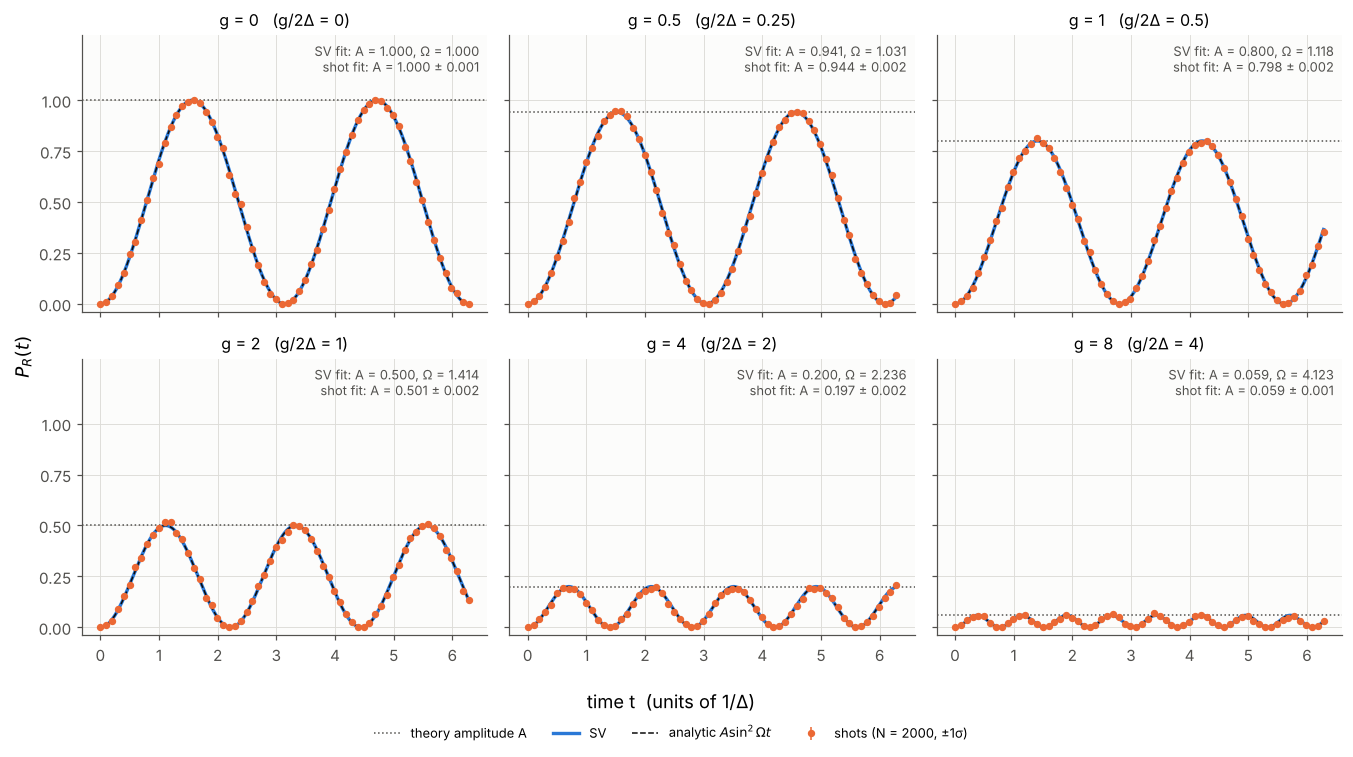

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.6), sharex=True, sharey=True)
m = TS <= 2 * np.pi
for ax, g in zip(axes.flat, G_VALUES):
    s, sh = series[g], shot_series[g]
    ax.axhline(amplitude(g), color=INK2, lw=1, ls=":", label="theory amplitude A")
    ax.plot(TS[m], s["P_R"][m], color=C1, lw=2.2, label="SV")
    ax.plot(TS[m], analytic_PR(g, TS[m]), color=INK, lw=1, ls="--", label=r"analytic $A\sin^2\Omega t$")
    ax.errorbar(sh["t"], sh["P_R"], yerr=sh["sigma"], fmt="o", ms=3.8, color=C2, elinewidth=1,
                capsize=0, label=f"shots (N = {SHOTS_SWEEP}, ±1σ)", zorder=5)
    ax.set_title(f"g = {g:g}   (g/2Δ = {g / 2 / DELTA:g})")
    ax.text(0.98, 0.97, f"SV fit: A = {fits_sv[g]['A']:.3f}, Ω = {fits_sv[g]['Om']:.3f}\n"
                        f"shot fit: A = {sh['A']:.3f} ± {sh['A_err']:.3f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2)
    ax.set_ylim(-0.04, 1.32)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
fig.supxlabel("time t  (units of 1/Δ)")
fig.supylabel(r"$P_R(t)$")
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.045))
fig.tight_layout()
save(fig, "F2_PR_vs_time")

shots, 1/A = a + b g^2:   b = 0.2507 +/- 0.0014,  a = 1.0002 +/- 0.0005
shots, Om^2 = a + b g^2:  b = 0.2501 +/- 0.0002,  a = 1.0002 +/- 0.0005
Delta from data: 0.9987 +/- 0.0028 (1/A slope), 1.0001 +/- 0.0003 (Om^2 intercept)
SV, all g <= 32: 1/A slope 0.250000, intercept 1.000000;  Om^2 slope 0.250000, intercept 1.000000


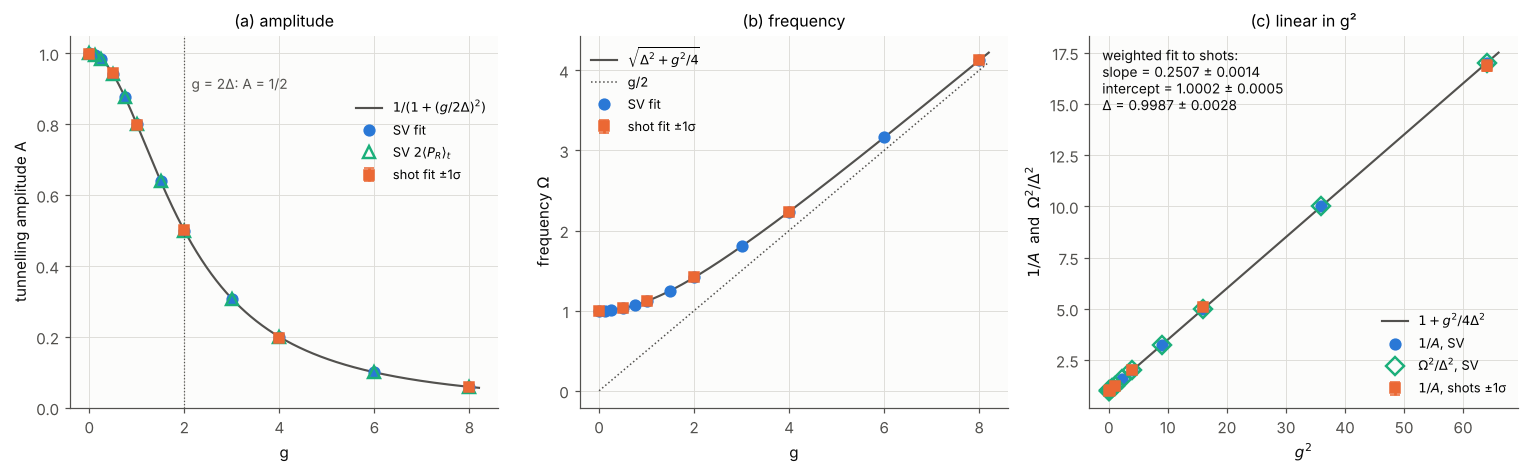

In [12]:
gs = [g for g in G_SWEEP if g <= 8]
A_sv = np.array([fits_sv[g]["A"] for g in gs])
Om_sv = np.array([fits_sv[g]["Om"] for g in gs])
A_sh = np.array([shot_series[g]["A"] for g in G_VALUES])
dA_sh = np.array([shot_series[g]["A_err"] for g in G_VALUES])
Om_sh = np.array([shot_series[g]["Om"] for g in G_VALUES])
dOm_sh = np.array([shot_series[g]["Om_err"] for g in G_VALUES])
x_sh = np.array(G_VALUES) ** 2

(b_A, a_A), cov_A = np.polyfit(x_sh, 1 / A_sh, 1, w=A_sh ** 2 / dA_sh, cov="unscaled")
(b_O, a_O), cov_O = np.polyfit(x_sh, Om_sh ** 2, 1, w=1 / (2 * Om_sh * dOm_sh), cov="unscaled")
db_A, da_A = np.sqrt(np.diag(cov_A))
db_O, da_O = np.sqrt(np.diag(cov_O))
Delta_slope = 1 / (2 * np.sqrt(b_A))
dDelta_slope = Delta_slope * db_A / (2 * b_A)
Delta_int = np.sqrt(a_O)
dDelta_int = da_O / (2 * Delta_int)
b_A_sv, a_A_sv = np.polyfit(np.array(G_SWEEP) ** 2, 1 / np.array([fits_sv[g]["A"] for g in G_SWEEP]), 1)
b_O_sv, a_O_sv = np.polyfit(np.array(G_SWEEP) ** 2, np.array([fits_sv[g]["Om"] for g in G_SWEEP]) ** 2, 1)
linear_law = dict(shots_invA_slope=[b_A, db_A], shots_invA_intercept=[a_A, da_A],
                  shots_Om2_slope=[b_O, db_O], shots_Om2_intercept=[a_O, da_O],
                  Delta_from_invA_slope=[Delta_slope, dDelta_slope], Delta_from_Om2_intercept=[Delta_int, dDelta_int],
                  sv_invA=[b_A_sv, a_A_sv], sv_Om2=[b_O_sv, a_O_sv])
print("shots, 1/A = a + b g^2:   b = %.4f +/- %.4f,  a = %.4f +/- %.4f" % (b_A, db_A, a_A, da_A))
print("shots, Om^2 = a + b g^2:  b = %.4f +/- %.4f,  a = %.4f +/- %.4f" % (b_O, db_O, a_O, da_O))
print("Delta from data: %.4f +/- %.4f (1/A slope), %.4f +/- %.4f (Om^2 intercept)" % (Delta_slope, dDelta_slope, Delta_int, dDelta_int))
print("SV, all g <= 32: 1/A slope %.6f, intercept %.6f;  Om^2 slope %.6f, intercept %.6f" % (b_A_sv, a_A_sv, b_O_sv, a_O_sv))
write_json("linear_law_fit.json", linear_law)

g_line = np.linspace(0, 8.2, 400)
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4.4))
a1.plot(g_line, amplitude(g_line), color=INK2, lw=1.4, label=r"$1/(1+(g/2\Delta)^2)$")
a1.plot(gs, A_sv, "o", color=C1, ms=7, label="SV fit")
a1.plot(gs, [fits_sv[g]["mean2"] for g in gs], "^", color=C3, ms=8, mfc="none", mew=1.6,
        label=r"SV $2\langle P_R\rangle_t$")
a1.errorbar(G_VALUES, A_sh, yerr=dA_sh, fmt="s", ms=6, color=C2, capsize=3, label="shot fit ±1σ")
a1.axvline(2 * DELTA, color=INK2, lw=0.8, ls=":")
a1.text(2.15 * DELTA, 0.9, "g = 2Δ: A = 1/2", color=INK2, fontsize=9)
a1.set(xlabel="g", ylabel="tunnelling amplitude A", title="(a) amplitude", ylim=(0, 1.05))
a1.legend(loc="upper right", bbox_to_anchor=(1.0, 0.86))

a2.plot(g_line, omega(g_line), color=INK2, lw=1.4, label=r"$\sqrt{\Delta^2+g^2/4}$")
a2.plot(g_line, g_line / 2, color=INK2, lw=1, ls=":", label="g/2")
a2.plot(gs, Om_sv, "o", color=C1, ms=7, label="SV fit")
a2.errorbar(G_VALUES, Om_sh, yerr=dOm_sh, fmt="s", ms=6, color=C2, capsize=3, label="shot fit ±1σ")
a2.set(xlabel="g", ylabel=r"frequency $\Omega$", title="(b) frequency")
a2.legend(loc="upper left")

x_line = np.linspace(0, 66, 200)
a3.plot(x_line, 1 + x_line / (4 * DELTA ** 2), color=INK2, lw=1.4, label=r"$1+g^2/4\Delta^2$")
a3.plot(np.array(gs) ** 2, 1 / A_sv, "o", color=C1, ms=7, label=r"$1/A$, SV")
a3.plot(np.array(gs) ** 2, Om_sv ** 2 / DELTA ** 2, "D", color=C3, ms=8, mfc="none", mew=1.6, label=r"$\Omega^2/\Delta^2$, SV")
a3.errorbar(x_sh, 1 / A_sh, yerr=dA_sh / A_sh ** 2, fmt="s", ms=6, color=C2, capsize=3, label=r"$1/A$, shots ±1σ")
a3.text(0.03, 0.97, f"weighted fit to shots:\nslope = {b_A:.4f} ± {db_A:.4f}\n"
                    f"intercept = {a_A:.4f} ± {da_A:.4f}\nΔ = {Delta_slope:.4f} ± {dDelta_slope:.4f}",
        transform=a3.transAxes, va="top", fontsize=9, color=INK)
a3.set(xlabel=r"$g^2$", ylabel=r"$1/A$  and  $\Omega^2/\Delta^2$", title="(c) linear in g²")
a3.legend(loc="lower right")
fig.tight_layout()
save(fig, "F3_tunnelling_trend")

## 6. Trotter accuracy (F4, F5)

Convergence uses SV only (maximum over $t \in [0, 10]$ at $g = 2$ and $8$), so the only error is the Trotter error. Shot noise enters as the floor $0.5/\sqrt N$ and through a $\chi^2$ visibility test at $g = 2$.

log-log slopes (4 smallest dt):    infidelity | max dP_R | max dC | ||dU||
  g=2,order=1       2.00     |   2.00   |  1.00  |  1.00
  g=2,order=2       4.00     |   2.00   |  2.00  |  2.00
  g=8,order=1       2.01     |   2.00   |  1.01  |  1.04
  g=8,order=2       4.00     |   2.00   |  2.00  |  2.00
||U_T - U|| <= bound in all 32 runs; measured/bound = 0.01-0.25
max |dP_R| at g = 2, n = 25..400:  T1 1.04e-01 2.51e-02 6.26e-03 1.57e-03 3.92e-04
                                   T2 1.11e-01 2.77e-02 6.97e-03 1.75e-03 4.37e-04
largest scanned dt with max |dP_R| below 0.5/sqrt(N):
  g=2,order=1,N=1000       dt <= 0.1
  g=2,order=1,N=10000      dt <= 0.05
  g=2,order=2,N=1000       dt <= 0.1
  g=2,order=2,N=10000      dt <= 0.05
  g=8,order=1,N=1000       dt <= 0.1
  g=8,order=1,N=10000      dt <= 0.05
  g=8,order=2,N=1000       dt <= 0.1
  g=8,order=2,N=10000      dt <= 0.05


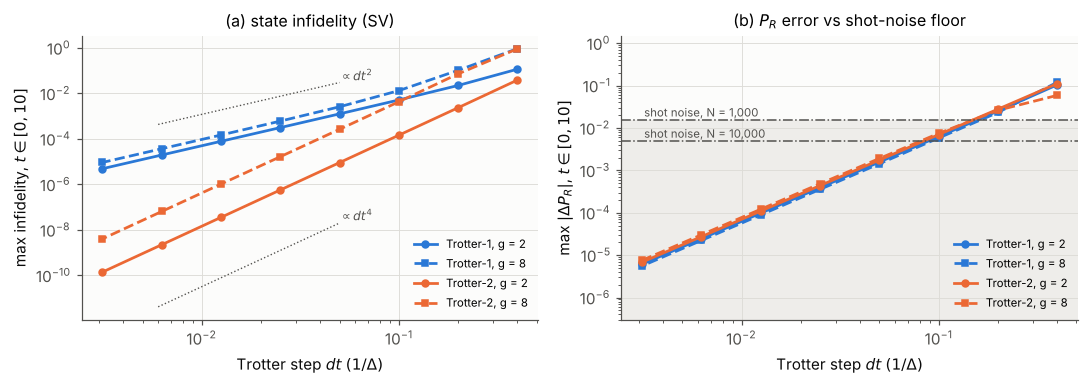

In [13]:
N_LIST = [25, 50, 100, 200, 400, 800, 1600, 3200]
G_CONV = (2.0, 8.0)
conv = []
for g in G_CONV:
    for order in (1, 2):
        for n in N_LIST:
            dt = T_MAX / n
            tt_, st = trotter_trajectory(g, n, dt, 1, order)
            ex = exact_trajectory(g, tt_)
            conv.append(dict(g=g, order=order, n=n, dt=dt,
                             infid=float(np.max(infidelity_many(st, ex))),
                             dP=float(np.max(np.abs(p_right_many(st) - p_right_many(ex)))),
                             dC=float(np.max(np.abs(concurrence_many(st) - concurrence_many(ex)))),
                             dU=float(np.linalg.norm(trotter_unitary(g, T_MAX, n, order) - exact_unitary(g, T_MAX), 2)),
                             bound=trotter_error_bound(g, T_MAX, n, order)))
assert all(r["dU"] <= r["bound"] for r in conv)


def slope(g, order, key, k=4):
    r = [x for x in conv if x["g"] == g and x["order"] == order][-k:]
    return float(np.polyfit(np.log([x["dt"] for x in r]), np.log([x[key] for x in r]), 1)[0])


def get(g, o, n, key):
    return next(x[key] for x in conv if x["g"] == g and x["order"] == o and x["n"] == n)


slopes = {f"g={g:g},order={o}": {k: round(slope(g, o, k), 2) for k in ("infid", "dP", "dC", "dU")}
          for g in G_CONV for o in (1, 2)}
print("log-log slopes (4 smallest dt):    infidelity | max dP_R | max dC | ||dU||")
for k, v in slopes.items():
    print(f"  {k:14s}  {v['infid']:6.2f}     | {v['dP']:6.2f}   | {v['dC']:5.2f}  | {v['dU']:5.2f}")
ratios = [r["dU"] / r["bound"] for r in conv]
print(f"||U_T - U|| <= bound in all {len(conv)} runs; measured/bound = {min(ratios):.2f}-{max(ratios):.2f}")
print("max |dP_R| at g = 2, n = 25..400:  T1", " ".join(f"{get(2.0, 1, n, 'dP'):.2e}" for n in (25, 50, 100, 200, 400)))
print("                                   T2", " ".join(f"{get(2.0, 2, n, 'dP'):.2e}" for n in (25, 50, 100, 200, 400)))

floors = {1000: 0.5 / math.sqrt(1000), 10000: 0.5 / math.sqrt(10000)}
invisible = {f"g={g:g},order={o},N={N_}": max([x["dt"] for x in conv if x["g"] == g and x["order"] == o and x["dP"] < fl],
                                               default=None)
             for g in G_CONV for o in (1, 2) for N_, fl in floors.items()}
print("largest scanned dt with max |dP_R| below 0.5/sqrt(N):")
for k, v in invisible.items():
    print(f"  {k:24s} dt <= {v}")
SUMMARY["trotter_convergence"] = dict(N_LIST=N_LIST, slopes=slopes, floors=floors, dt_invisible=invisible,
                                      ratio_min=min(ratios), ratio_max=max(ratios),
                                      prod_dt={g: T_MAX / steps_for_tolerance(g, T_MAX, TROTTER_TOL, 2) for g in G_VALUES})
write_csv("trotter_convergence.csv", list(conv[0]), [list(r.values()) for r in conv])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
style = {(2.0, 1): dict(color=C1, ls="-", marker="o"), (8.0, 1): dict(color=C1, ls="--", marker="s"),
         (2.0, 2): dict(color=C2, ls="-", marker="o"), (8.0, 2): dict(color=C2, ls="--", marker="s")}
for (g, o), s in style.items():
    r = [x for x in conv if x["g"] == g and x["order"] == o]
    dts = [x["dt"] for x in r]
    a1.loglog(dts, [x["infid"] for x in r], ms=4.5, label=f"Trotter-{o}, g = {g:g}", **s)
    a2.loglog(dts, [x["dP"] for x in r], ms=4.5, label=f"Trotter-{o}, g = {g:g}", **s)
d = np.array([0.006, 0.05])
a1.loglog(d, 3e-2 * (d / 0.05) ** 2, color=INK2, lw=0.9, ls=":")
a1.text(0.05, 3.6e-2, r"$\propto dt^2$", color=INK2, fontsize=8)
a1.loglog(d, 2e-8 * (d / 0.05) ** 4, color=INK2, lw=0.9, ls=":")
a1.text(0.05, 2.5e-8, r"$\propto dt^4$", color=INK2, fontsize=8)
a1.set(xlabel=r"Trotter step $dt$ $(1/\Delta)$", ylabel=r"max infidelity, $t\in[0,10]$", title="(a) state infidelity (SV)")
a1.legend(loc="lower right", fontsize=7.5)
for N_, fl in floors.items():
    a2.axhline(fl, color=INK2, lw=1, ls="-.")
    a2.text(0.0032, fl * 1.18, f"shot noise, N = {N_:,}", color=INK2, fontsize=7.5)
a2.axhspan(1e-9, floors[1000], color=GRID, alpha=0.45, lw=0)
a2.set(xlabel=r"Trotter step $dt$ $(1/\Delta)$", ylabel=r"max $|\Delta P_R|$, $t\in[0,10]$",
       title=r"(b) $P_R$ error vs shot-noise floor", ylim=(3e-7, 1.5))
a2.legend(loc="lower right", fontsize=7.5)
fig.tight_layout()
save(fig, "F4_trotter_convergence")

In [14]:
g = 2.0
t_vis = np.round(np.arange(0.5, T_MAX + 1e-9, 0.5), 10)
p_true = analytic_PR(g, t_vis)
vis = []
for order in (1, 2):
    for per_half in (1, 4, 20):
        dt = 0.5 / per_half
        circs = [trotter_circuit(g, t, int(round(t / dt)), order) for t in t_vis]
        p_sv = np.array([p_right(Statevector.from_instruction(c)) for c in circs])
        for N_ in (1000, 10000):
            sig = shot_noise(p_true, N_)
            chis = []
            for k in range(5):
                cs = sample_counts(circs, shots=N_, seed=SEED + 1000 * order + 50 * per_half + 10 * k + (N_ > 1000))
                p = np.array([p_right_from_counts(c)[0] for c in cs])
                chis.append(np.mean(((p - p_true) / sig) ** 2))
            vis.append(dict(order=order, dt=dt, N=N_, chi2=float(np.mean(chis)),
                            chi2_pred=float(1 + np.mean(((p_sv - p_true) / sig) ** 2)),
                            max_dP=float(np.max(np.abs(p_sv - p_true)))))
print("g = 2, 20 times, 5 seeds per row")
print(f"{'order':>5} {'dt':>6} {'N':>6} | {'max|dP_R| SV':>12} | {'chi2/dof':>8} {'predicted':>9}")
for r in vis:
    print(f"{r['order']:5d} {r['dt']:6.3f} {r['N']:6d} | {r['max_dP']:12.2e} | {r['chi2']:8.2f} {r['chi2_pred']:9.2f}")
SUMMARY["shot_visibility"] = vis
write_csv("shot_visibility.csv", list(vis[0]), [list(r.values()) for r in vis])

g = 2, 20 times, 5 seeds per row
order     dt      N | max|dP_R| SV | chi2/dof predicted
    1  0.500   1000 |     1.60e-01 |    43.56     43.91
    1  0.500  10000 |     1.60e-01 |   426.16    430.13
    1  0.125   1000 |     8.13e-03 |     1.22      1.15
    1  0.125  10000 |     8.13e-03 |     2.69      2.52
    1  0.025   1000 |     3.20e-04 |     0.82      1.00
    1  0.025  10000 |     3.20e-04 |     1.01      1.00
    2  0.500   1000 |     1.62e-01 |    34.04     34.26
    2  0.500  10000 |     1.62e-01 |   336.27    333.64
    2  0.125   1000 |     1.09e-02 |     1.02      1.16
    2  0.125  10000 |     1.09e-02 |     2.24      2.61
    2  0.025   1000 |     4.36e-04 |     0.99      1.00
    2  0.025  10000 |     4.36e-04 |     0.93      1.00


In [15]:
def z1_max(states):
    pr = np.abs(np.asarray(states)) ** 2
    return float(np.max(np.abs(pr[:, 0] + pr[:, 1] - pr[:, 2] - pr[:, 3])))


cons = []
times = time_grid()
for g in G_VALUES:
    ex = exact_trajectory(g, times)
    _, coarse = trotter_trajectory(g, 20, 0.5, 1, 1)
    n2 = steps_for_tolerance(g, T_MAX, TROTTER_TOL, 2)
    _, prod = trotter_trajectory(g, len(times) - 1, DT_OUT, math.ceil(n2 / (len(times) - 1)), 2)
    circ = [Statevector.from_instruction(exact_circuit(g, t)).data for t in times[::10]]
    cons.append(dict(g=g, expm=z1_max(ex), exact_circuit=z1_max(circ), trotter1_dt05=z1_max(coarse),
                     trotter2_prod=z1_max(prod)))
print(f"{'g':>4} | max |<Z1>|: {'expm':>9} {'exact circ':>10} {'T1 dt=0.5':>10} {'T2 prod':>9}")
for r in cons:
    print(f"{r['g']:4.1f} |             {r['expm']:9.1e} {r['exact_circuit']:10.1e} {r['trotter1_dt05']:10.1e} {r['trotter2_prod']:9.1e}")
worst = max(max(v for k, v in r.items() if k != "g") for r in cons)
assert worst < 1e-12
print(f"worst case: {worst:.1e}")
SUMMARY["z1_conservation"] = dict(table=cons, worst=worst)
write_csv("z1_conservation.csv", list(cons[0]), [list(r.values()) for r in cons])

   g | max |<Z1>|:      expm exact circ  T1 dt=0.5   T2 prod
 0.0 |               5.6e-17    2.2e-16    5.6e-17   5.6e-17
 0.5 |               2.2e-16    2.2e-16    5.6e-17   5.6e-17
 1.0 |               2.8e-16    1.1e-16    5.6e-17   5.6e-17
 2.0 |               2.9e-16    1.4e-16    5.6e-17   5.6e-17
 4.0 |               1.9e-16    3.1e-16    5.6e-17   2.8e-17
 8.0 |               3.7e-16    3.4e-16    5.6e-17   5.6e-17
worst case: 3.7e-16


   g      dt     n    bound  max|dP| |   A fit    A th |  Om fit   Om th
 0.0  0.0500   200  0.0e+00  4.8e-14 |  1.0000  1.0000 |  1.0000  1.0000
 0.5  0.0250   400  3.9e-04  6.6e-05 |  0.9412  0.9412 |  1.0308  1.0308
 1.0  0.0167   600  4.6e-04  8.8e-05 |  0.8000  0.8000 |  1.1180  1.1180
 2.0  0.0125   800  7.8e-04  1.1e-04 |  0.5000  0.5000 |  1.4142  1.4142
 4.0  0.0071  1400  8.5e-04  4.2e-05 |  0.2000  0.2000 |  2.2361  2.2361
 8.0  0.0038  2600  8.9e-04  1.1e-05 |  0.0588  0.0588 |  4.1231  4.1231
Trotter-2 fits vs theory: max |dA| = 3.9e-05, max relative dOmega = 1.3e-05


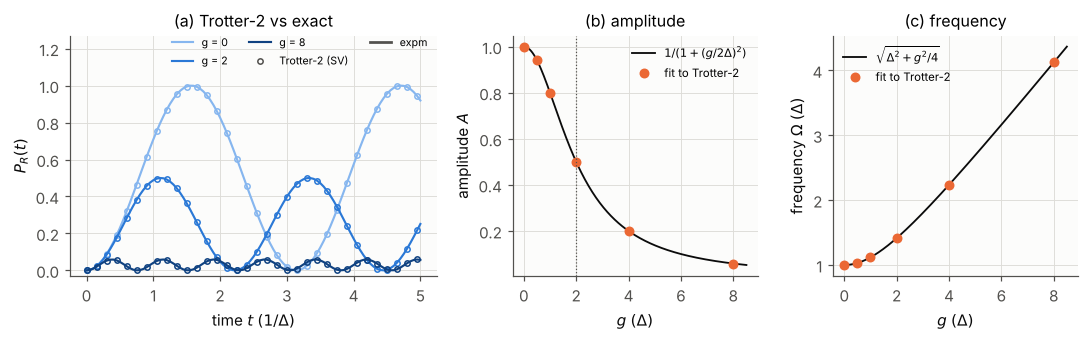

In [16]:
times = time_grid()
n_out = len(times) - 1
sweep, traj = [], {}
for g in G_VALUES:
    sub = max(1, math.ceil(steps_for_tolerance(g, T_MAX, TROTTER_TOL, 2) / n_out))
    tt_, st = trotter_trajectory(g, n_out, DT_OUT, sub, 2)
    p_tr, p_ex = p_right_many(st), p_right_many(exact_trajectory(g, tt_))
    (A_t, W_t), _, _ = fit_rabi(tt_, p_tr)
    (A_e, W_e), _, _ = fit_rabi(tt_, p_ex)
    traj[g] = (tt_, p_tr, p_ex)
    sweep.append(dict(g=g, dt=DT_OUT / sub, n_total=sub * n_out,
                      bound=trotter_error_bound(g, T_MAX, sub * n_out, 2),
                      max_dP=float(np.max(np.abs(p_tr - p_ex))),
                      A_trotter=A_t, A_exactfit=A_e, A_theory=float(amplitude(g)),
                      W_trotter=W_t, W_exactfit=W_e, W_theory=float(omega(g)),
                      Cmax_trotter=float(concurrence_many(st).max())))
print(f"{'g':>4} {'dt':>7} {'n':>5} {'bound':>8} {'max|dP|':>8} | {'A fit':>7} {'A th':>7} | {'Om fit':>7} {'Om th':>7}")
for r in sweep:
    print(f"{r['g']:4.1f} {r['dt']:7.4f} {r['n_total']:5d} {r['bound']:8.1e} {r['max_dP']:8.1e} | "
          f"{r['A_trotter']:7.4f} {r['A_theory']:7.4f} | {r['W_trotter']:7.4f} {r['W_theory']:7.4f}")
dA = max(abs(r["A_trotter"] - r["A_theory"]) for r in sweep)
dW = max(abs(r["W_trotter"] - r["W_theory"]) / r["W_theory"] for r in sweep)
print(f"Trotter-2 fits vs theory: max |dA| = {dA:.1e}, max relative dOmega = {dW:.1e}")
assert dA < 5e-3 and dW < 5e-3
SUMMARY["trotter_gsweep"] = dict(table=sweep, max_dA=dA, max_rel_dW=dW)
write_csv("trotter_gsweep.csv", list(sweep[0]), [list(r.values()) for r in sweep])

fig, (b1, b2, b3) = plt.subplots(1, 3, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
for g in (0.0, 2.0, 8.0):
    tt_, p_tr, p_ex = traj[g]
    sel = tt_ <= 5 + 1e-9
    b1.plot(tt_[sel], p_ex[sel], color=SEQ[g], lw=1.4, label=f"g = {g:g}")
    b1.plot(tt_[sel][::3], p_tr[sel][::3], "o", ms=3.5, mfc="none", mec=SEQ[g], mew=1)
b1.plot([], [], "o", ms=3.5, mfc="none", mec=INK2, label="Trotter-2 (SV)")
b1.plot([], [], "-", color=INK2, label="expm")
b1.set(xlabel=r"time $t$ $(1/\Delta)$", ylabel=r"$P_R(t)$", title="(a) Trotter-2 vs exact", ylim=(-0.03, 1.27))
b1.legend(ncol=3, loc="upper right", fontsize=7, bbox_to_anchor=(1, 1.04))
gg = np.linspace(0, 8.5, 300)
b2.plot(gg, amplitude(gg), color=INK, lw=1.2, label=r"$1/(1+(g/2\Delta)^2)$")
b2.plot([r["g"] for r in sweep], [r["A_trotter"] for r in sweep], "o", ms=5.5, color=C2, label="fit to Trotter-2")
b2.axvline(2, color=INK2, lw=0.8, ls=":")
b2.set(xlabel=r"$g$ $(\Delta)$", ylabel=r"amplitude $A$", title="(b) amplitude")
b2.legend(fontsize=7.5)
b3.plot(gg, omega(gg), color=INK, lw=1.2, label=r"$\sqrt{\Delta^2+g^2/4}$")
b3.plot([r["g"] for r in sweep], [r["W_trotter"] for r in sweep], "o", ms=5.5, color=C2, label="fit to Trotter-2")
b3.set(xlabel=r"$g$ $(\Delta)$", ylabel=r"frequency $\Omega$ $(\Delta)$", title="(c) frequency")
b3.legend(fontsize=7.5)
fig.tight_layout()
save(fig, "F5_trotter_gsweep")

## 7. Spin dynamics and position–spin correlations (F6, F7)

Diagnostics: spin Bloch vector $(\langle X_1\rangle, \langle Y_1\rangle, \langle Z_1\rangle)$, pure-state concurrence $C = 2|a_{00}a_{11} - a_{01}a_{10}|$, and connected correlators $\langle P_0P_1\rangle - \langle P_0\rangle\langle P_1\rangle$ (all SV).

max |<Z1>|               = 2.8e-16
max |C - (g/Delta) P_R|  = 5.6e-16
max ||r| - sqrt(1 - C^2)| = 3.9e-12
max |C - analytic C|     = 4.7e-15
g = 2, t* = 1.1107: C = 1.000000, |r| = 2.3e-16


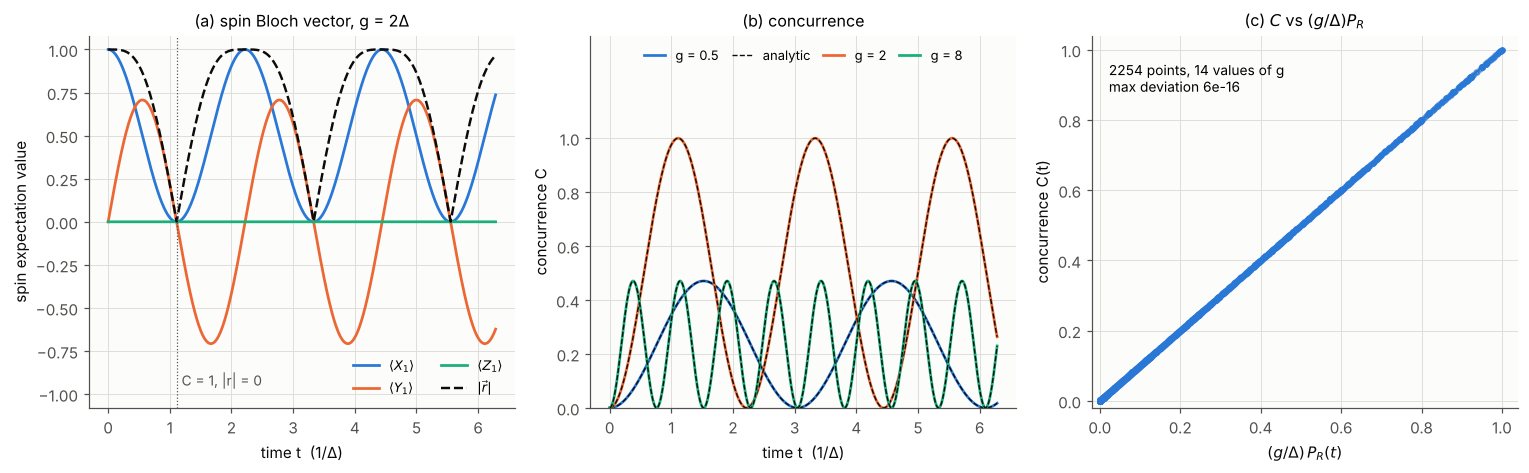

In [17]:
g0 = 2.0
t_star = np.pi / (2 * float(omega(g0)))
s = series[g0]
m = TS <= 2 * np.pi
r_len = np.sqrt(s["sx"] ** 2 + s["sy"] ** 2 + s["sz"] ** 2)

max_sz = max(np.abs(series[g]["sz"]).max() for g in G_SWEEP)
max_rel = max(np.abs(series[g]["C"] - g / DELTA * series[g]["P_R"]).max() for g in G_SWEEP)
max_r = max(np.abs(np.sqrt(series[g]["sx"] ** 2 + series[g]["sy"] ** 2 + series[g]["sz"] ** 2)
                   - np.sqrt(np.clip(1 - series[g]["C"] ** 2, 0, None))).max() for g in G_SWEEP)
max_cth = max(np.abs(series[g]["C"] - analytic_concurrence(g, TS)).max() for g in G_SWEEP)
S_t = exact_trajectory(g0, [t_star])
print(f"max |<Z1>|               = {max_sz:.1e}")
print(f"max |C - (g/Delta) P_R|  = {max_rel:.1e}")
print(f"max ||r| - sqrt(1 - C^2)| = {max_r:.1e}")
print(f"max |C - analytic C|     = {max_cth:.1e}")
print(f"g = 2, t* = {t_star:.4f}: C = {concurrence_many(S_t)[0]:.6f}, |r| = {np.linalg.norm(spin_bloch(S_t)[0]):.1e}")

fig, (b1, b2, b3) = plt.subplots(1, 3, figsize=(14, 4.4))
b1.plot(TS[m], s["sx"][m], color=C1, label=r"$\langle X_1\rangle$")
b1.plot(TS[m], s["sy"][m], color=C2, label=r"$\langle Y_1\rangle$")
b1.plot(TS[m], s["sz"][m], color=C3, label=r"$\langle Z_1\rangle$")
b1.plot(TS[m], r_len[m], color=INK, lw=1.6, ls="--", label=r"$|\vec r|$")
b1.axvline(t_star, color=INK2, lw=0.8, ls=":")
b1.text(t_star + 0.08, -0.95, "C = 1, |r| = 0", fontsize=9, color=INK2)
b1.set(xlabel="time t  (1/Δ)", ylabel="spin expectation value", title="(a) spin Bloch vector, g = 2Δ", ylim=(-1.08, 1.08))
b1.legend(loc="lower right", ncol=2, fontsize=8.5)
for g, col in zip([0.5, 2.0, 8.0], [C1, C2, C3]):
    b2.plot(TS[m], series[g]["C"][m], color=col, label=f"g = {g:g}")
    b2.plot(TS[m], analytic_concurrence(g, TS[m]), color=INK, lw=0.9, ls="--", label="analytic" if g == 0.5 else None)
b2.set(xlabel="time t  (1/Δ)", ylabel="concurrence C", title="(b) concurrence", ylim=(0, 1.38))
b2.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
b2.legend(loc="upper center", ncol=4, fontsize=8.5, columnspacing=1.0, handlelength=1.6)
xs = np.concatenate([g / DELTA * series[g]["P_R"][::25] for g in G_SWEEP if g > 0])
ys = np.concatenate([series[g]["C"][::25] for g in G_SWEEP if g > 0])
b3.plot([0, 1], [0, 1], color=INK2, lw=1)
b3.plot(xs, ys, "o", color=C1, ms=3.2, alpha=0.55)
b3.text(0.04, 0.93, f"{len(xs)} points, {len(G_SWEEP) - 1} values of g\nmax deviation {max_rel:.0e}",
        transform=b3.transAxes, fontsize=9, va="top")
b3.set(xlabel=r"$(g/\Delta)\,P_R(t)$", ylabel="concurrence C(t)", title=r"(c) $C$ vs $(g/\Delta)P_R$",
       xlim=(-0.02, 1.04), ylim=(-0.02, 1.04))
fig.tight_layout()
save(fig, "F6_spin_and_concurrence")

connected correlators at g = 2, t = t* (0 = position, 1 = spin):
  <X0 X1> = +0.000   <X0 Y1> = +0.000   <X0 Z1> = +1.000   <Y0 X1> = +0.000   <Y0 Y1> = -1.000   <Y0 Z1> = +0.000   <Z0 X1> = -1.000   <Z0 Y1> = -0.000   <Z0 Z1> = +0.000
C_max (SV): g=0.125: 0.125, g=0.25: 0.246, g=0.5: 0.471, g=0.75: 0.658, g=1: 0.800, g=1.5: 0.960, g=2: 1.000, g=3: 0.923, g=4: 0.800, g=6: 0.600, g=8: 0.471, g=12: 0.324, g=16: 0.246, g=32: 0.125


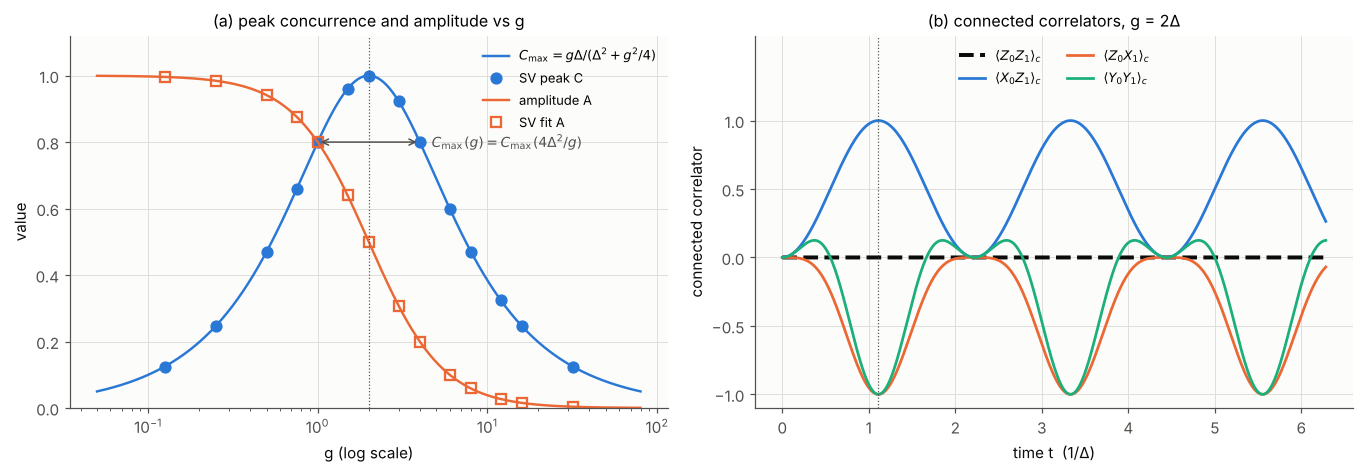

In [18]:
g_log = np.geomspace(0.05, 80, 500)
x = g_log / (2 * DELTA)
gs_pos = [g for g in G_SWEEP if g > 0]
Cmax_sv = np.array([series[g]["C"].max() for g in gs_pos])

pairs = [(p, q) for p in "XYZ" for q in "XYZ"]
corr_exact = {f"{p}0{q}1": float(connected(S_t, p, q)[0]) for p, q in pairs}
print("connected correlators at g = 2, t = t* (0 = position, 1 = spin):")
print("  " + "   ".join(f"<{k[:2]} {k[2:]}> = {v:+.3f}" for k, v in corr_exact.items()))
print("C_max (SV):", ", ".join(f"g={g:g}: {c:.3f}" for g, c in zip(gs_pos, Cmax_sv)))

fig, (c1, c2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
c1.semilogx(g_log, 2 * x / (1 + x ** 2), color=C1, lw=1.6, label=r"$C_{\max}=g\Delta/(\Delta^2+g^2/4)$")
c1.semilogx(gs_pos, Cmax_sv, "o", color=C1, ms=7, label="SV peak C")
c1.semilogx(g_log, 1 / (1 + x ** 2), color=C2, lw=1.6, label="amplitude A")
c1.semilogx(gs_pos, [fits_sv[g]["A"] for g in gs_pos], "s", color=C2, ms=6, mfc="none", mew=1.5, label="SV fit A")
c1.axvline(2 * DELTA, color=INK2, lw=0.8, ls=":")
c1.annotate("", xy=(4, 0.8), xytext=(1, 0.8), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
c1.text(4.7, 0.80, r"$C_{\max}(g)=C_{\max}(4\Delta^2/g)$", ha="left", va="center", fontsize=9, color=INK2)
c1.set(xlabel="g (log scale)", ylabel="value", ylim=(0, 1.12), title="(a) peak concurrence and amplitude vs g")
c1.legend(loc="upper right", fontsize=8.5)
ts2, S2 = TS[m], series[g0]["states"][m]
c2.plot(ts2, connected(S2, "Z", "Z"), color=INK, lw=2.6, ls="--", label=r"$\langle Z_0Z_1\rangle_c$")
c2.plot(ts2, connected(S2, "X", "Z"), color=C1, label=r"$\langle X_0Z_1\rangle_c$")
c2.plot(ts2, connected(S2, "Z", "X"), color=C2, label=r"$\langle Z_0X_1\rangle_c$")
c2.plot(ts2, connected(S2, "Y", "Y"), color=C3, label=r"$\langle Y_0Y_1\rangle_c$")
c2.axvline(t_star, color=INK2, lw=0.8, ls=":")
c2.set(xlabel="time t  (1/Δ)", ylabel="connected correlator", ylim=(-1.1, 1.62), yticks=[-1, -0.5, 0, 0.5, 1],
       title="(b) connected correlators, g = 2Δ")
c2.legend(loc="upper center", fontsize=8.5, ncol=2)
fig.tight_layout()
save(fig, "F7_entanglement_vs_g")
write_csv("cmax_vs_g.csv", ["g", "Cmax_sv", "Cmax_theory"],
          [[g, c, g * DELTA / (DELTA ** 2 + g ** 2 / 4)] for g, c in zip(gs_pos, Cmax_sv)])

## 8. Entanglement from measurement data (F8)

Shots on the exact circuit, 9-setting two-qubit tomography (linear inversion, projection to the nearest physical state), 2000 shots per setting, 10 seeds. Estimators: spin Bloch vector $\sqrt{1-|\vec r|^2}$ (valid only for a pure global state), tomography concurrence, and $2\times$ negativity. The last state is a control: $g = 0$ with the spin classically dephased (half the shots with a $Z$ on $q_1$).

In [19]:
TOMO_SHOTS, N_SEEDS = 2000, 10


def pauli_matrix(pos, spin):
    return SparsePauliOp(spin + pos).to_matrix()


def rotate(qc, qubit, basis):
    if basis == "X":
        qc.h(qubit)
    elif basis == "Y":
        qc.sdg(qubit)
        qc.h(qubit)


def tomography(components, shots, seed):
    sampler_t = StatevectorSampler(seed=np.random.default_rng(seed))
    jobs, keys = [], []
    for bp, bs in product("XYZ", repeat=2):
        for qc, wgt in components:
            c = qc.copy()
            rotate(c, POS, bp)
            rotate(c, SPIN, bs)
            c.measure_all()
            jobs.append((c, None, int(round(wgt * shots))))
            keys.append((bp, bs))
    pooled = {}
    for key, r in zip(keys, sampler_t.run(jobs).result()):
        for k, v in r.data.meas.get_counts().items():
            pooled.setdefault(key, {}).setdefault(k, 0)
            pooled[key][k] += v
    E, marg = {("I", "I"): 1.0}, {}
    for (bp, bs), cnts in pooled.items():
        n = sum(cnts.values())
        epp = ep = es = 0
        for k, v in cnts.items():
            ss, sp = (1 - 2 * bit(k, SPIN)), (1 - 2 * bit(k, POS))
            epp += sp * ss * v
            ep += sp * v
            es += ss * v
        E[(bp, bs)] = epp / n
        marg.setdefault((bp, "I"), []).append(ep / n)
        marg.setdefault(("I", bs), []).append(es / n)
    E.update({k: float(np.mean(v)) for k, v in marg.items()})
    return E


def rho_from(E):
    return sum(v * pauli_matrix(p, s) for (p, s), v in E.items()) / 4


def nearest_physical(rho):
    w, V = np.linalg.eigh((rho + rho.conj().T) / 2)
    w = np.clip(w, 0, None)
    w /= w.sum()
    return (V * w) @ V.conj().T


def negativity(rho):
    pt = rho.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)
    ev = np.linalg.eigvalsh((pt + pt.conj().T) / 2)
    return float(-ev[ev < 0].sum())


def corr_matrix(E):
    return np.array([[E[(p, q)] - E[(p, "I")] * E[("I", q)] for q in "XYZ"] for p in "XYZ"])


def dephase_spin(qc):
    c = qc.copy()
    c.z(SPIN)
    return c


t_peak_05 = np.pi / (2 * float(omega(0.5)))
test_states = [
    ("g=2, t*", [(exact_circuit(2.0, t_star), 1.0)]),
    ("g=2, t*/2", [(exact_circuit(2.0, t_star / 2), 1.0)]),
    ("g=0.5, peak", [(exact_circuit(0.5, t_peak_05), 1.0)]),
    ("g=0, t=1", [(exact_circuit(0.0, 1.0), 1.0)]),
    ("g=0, t=1, dephased spin", [(exact_circuit(0.0, 1.0), 0.5), (dephase_spin(exact_circuit(0.0, 1.0)), 0.5)]),
]

tomo, rows = {}, []
for name, comps in test_states:
    rho_exact = sum(w * DensityMatrix(qc).data for qc, w in comps)
    r_ex = [np.trace(rho_exact @ pauli_matrix("I", s)).real for s in "XYZ"]
    exact = dict(C=concurrence(DensityMatrix(rho_exact)), N2=2 * negativity(rho_exact),
                 bloch=np.sqrt(max(0, 1 - sum(v ** 2 for v in r_ex))))
    est = {"C_bloch": [], "C_tomo": [], "N2_tomo": [], "purity": [], "corr": []}
    for seed in range(N_SEEDS):
        E = tomography(comps, TOMO_SHOTS, seed=SEED_SWEEP + 100 * seed)
        rho = rho_from(E)
        rho_p = nearest_physical(rho)
        r = np.array([E[("I", s)] for s in "XYZ"])
        est["C_bloch"].append(np.sqrt(max(0.0, 1 - r @ r)))
        est["C_tomo"].append(concurrence(DensityMatrix(rho_p)))
        est["N2_tomo"].append(2 * negativity(rho))
        est["purity"].append(np.trace(rho_p @ rho_p).real)
        est["corr"].append(corr_matrix(E))
    tomo[name] = dict(exact=exact, **{k: np.array(v) for k, v in est.items()})
    t_ = tomo[name]
    rows.append([name, exact["C"], exact["bloch"], t_["C_bloch"].mean(), t_["C_bloch"].std(ddof=1),
                 t_["C_tomo"].mean(), t_["C_tomo"].std(ddof=1), t_["N2_tomo"].mean(), t_["N2_tomo"].std(ddof=1),
                 t_["purity"].mean()])

print(f"{'state':26} {'C exact':>8} {'C Bloch':>15} {'C tomo':>15} {'2N tomo':>15} {'purity':>7}")
for r in rows:
    print(f"{r[0]:26} {r[1]:8.3f} {r[3]:7.3f}+/-{r[4]:.3f} {r[5]:7.3f}+/-{r[6]:.3f} {r[7]:7.3f}+/-{r[8]:.3f} {r[9]:7.3f}")
print(f"mean +/- sd over {N_SEEDS} seeds, {TOMO_SHOTS} shots per setting")
write_csv("entanglement_from_shots.csv",
          ["state", "C_exact", "C_bloch_exact", "C_bloch_mean", "C_bloch_sd", "C_tomo_mean", "C_tomo_sd",
           "2N_tomo_mean", "2N_tomo_sd", "purity_tomo_mean"], rows)

state                       C exact         C Bloch          C tomo         2N tomo  purity
g=2, t*                       1.000   1.000+/-0.000   0.971+/-0.013   1.000+/-0.000   0.970
g=2, t*/2                     0.500   0.502+/-0.027   0.481+/-0.012   0.503+/-0.013   0.964
g=0.5, peak                   0.471   0.473+/-0.012   0.454+/-0.014   0.470+/-0.011   0.970
g=0, t=1                      0.000   0.000+/-0.000   0.015+/-0.010   0.028+/-0.008   0.972
g=0, t=1, dephased spin       0.000   1.000+/-0.000   0.006+/-0.009   0.013+/-0.006   0.494
mean +/- sd over 10 seeds, 2000 shots per setting


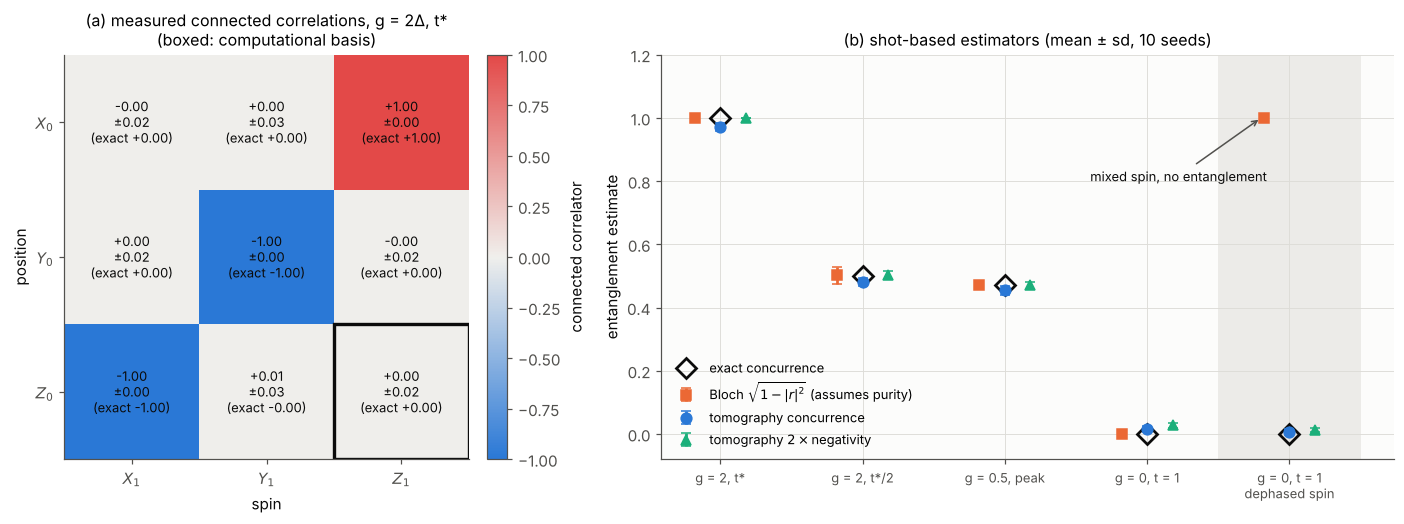

In [20]:
name0 = test_states[0][0]
Mmean = tomo[name0]["corr"].mean(0)
Mstd = tomo[name0]["corr"].std(0, ddof=1)
Mex = np.array([[corr_exact[f"{p}0{q}1"] for q in "XYZ"] for p in "XYZ"])

fig, (d1, d2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.6]))
im = d1.imshow(Mmean, cmap=DIVERGING, vmin=-1, vmax=1)
d1.grid(False)
for i in range(3):
    for j in range(3):
        d1.text(j, i, f"{Mmean[i, j]:+.2f}\n±{Mstd[i, j]:.2f}\n(exact {Mex[i, j]:+.2f})",
                ha="center", va="center", fontsize=8.5, color=INK)
d1.add_patch(Rectangle((1.5, 1.5), 1, 1, fill=False, ec=INK, lw=2.2))
d1.set_xticks(range(3), [r"$X_1$", r"$Y_1$", r"$Z_1$"])
d1.set_yticks(range(3), [r"$X_0$", r"$Y_0$", r"$Z_0$"])
d1.set(xlabel="spin", ylabel="position", title="(a) measured connected correlations, g = 2Δ, t*\n(boxed: computational basis)")
fig.colorbar(im, ax=d1, fraction=0.046, pad=0.04, label="connected correlator")

names = [n for n, _ in test_states]
xpos = np.arange(len(names))
d2.plot(xpos, [tomo[n]["exact"]["C"] for n in names], "D", color=INK, ms=9, mfc="none", mew=1.8, label="exact concurrence")
for off, key, col, mk, lab in [(-0.18, "C_bloch", C2, "s", r"Bloch $\sqrt{1-|r|^2}$ (assumes purity)"),
                               (0.0, "C_tomo", C1, "o", "tomography concurrence"),
                               (0.18, "N2_tomo", C3, "^", r"tomography $2\times$negativity")]:
    d2.errorbar(xpos + off, [tomo[n][key].mean() for n in names], yerr=[tomo[n][key].std(ddof=1) for n in names],
                fmt=mk, color=col, ms=7, capsize=3, label=lab)
d2.axvspan(3.5, 4.5, color=GRID, alpha=0.5, lw=0)
d2.set_xticks(xpos, ["g = 2, t*", "g = 2, t*/2", "g = 0.5, peak", "g = 0, t = 1", "g = 0, t = 1\ndephased spin"], fontsize=8.5)
d2.annotate("mixed spin, no entanglement", xy=(4 - 0.2, 1.0), xytext=(2.6, 0.8),
            fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="->", color=INK2, lw=1))
d2.set(ylabel="entanglement estimate", ylim=(-0.08, 1.2), title=f"(b) shot-based estimators (mean ± sd, {N_SEEDS} seeds)")
d2.legend(loc="lower left", fontsize=8.5)
fig.tight_layout()
save(fig, "F8_entanglement_from_shots")

## 9. Captions and summary

In [21]:
b0s, ll, tc, tg = SUMMARY["baseline_g0"], linear_law, SUMMARY["trotter_convergence"], SUMMARY["trotter_gsweep"]
sl = tc["slopes"]
CAPTIONS = {
    "F1_baseline_g0":
        f"Baseline, g = 0. (a) P_R(t): analytic sin²t (line), Trotter-2 SV (circles, max deviation {b0s['sv_max_err']:.0e}) "
        f"and shots (StatevectorSampler, N = {b0s['shots']}, ±1σ; χ²/dof = {b0s['chi2']:.2f}). A fit to the shots gives "
        f"amplitude {b0s['fit_A']:.3f} ± {b0s['fit_A_err']:.3f} and period {b0s['period']:.3f} ± {b0s['period_err']:.3f}. "
        f"(b) ⟨Z₁⟩ from shots at g = 0 and g = 2 (±1σ), grey band ±2/√N; SV |⟨Z₁⟩| < 1e-15.",
    "F2_PR_vs_time":
        f"P_R(t) for six values of g. Blue: SV. Black dashed: analytic A sin²(Ωt). Orange: shots (StatevectorSampler, exact circuit, "
        f"{SHOTS_SWEEP} shots per point, ±1σ). Dotted: A = 1/(1+(g/2Δ)²).",
    "F3_tunnelling_trend":
        f"(a) Tunnelling amplitude A vs g: SV fits, SV time average 2⟨P_R⟩, shot fits (±1σ), and 1/(1+(g/2Δ)²). "
        f"(b) Frequency Ω vs g against √(Δ²+g²/4). (c) 1/A and Ω²/Δ² vs g². Weighted fit to the shot data: slope "
        f"{ll['shots_invA_slope'][0]:.4f} ± {ll['shots_invA_slope'][1]:.4f}, intercept {ll['shots_invA_intercept'][0]:.4f} ± "
        f"{ll['shots_invA_intercept'][1]:.4f}, giving Δ = {ll['Delta_from_invA_slope'][0]:.4f} ± {ll['Delta_from_invA_slope'][1]:.4f}.",
    "F4_trotter_convergence":
        f"Trotter convergence at g = 2 (solid, circles) and g = 8 (dashed, squares); SV, maximum over t ∈ [0, 10]. "
        f"(a) Infidelity scales as dt^{sl['g=2,order=1']['infid']:.0f} (Trotter-1) and dt^{sl['g=2,order=2']['infid']:.0f} (Trotter-2). "
        f"(b) max |ΔP_R| scales as dt^{sl['g=2,order=1']['dP']:.0f} for both orders. Dash-dotted: shot noise 0.5/√N; "
        f"errors in the shaded region are below the N = 1000 noise.",
    "F5_trotter_gsweep":
        f"g-sweep with Trotter-2 (error bound ≤ {TROTTER_TOL:g}). (a) Trotter-2 SV (circles) and expm (lines) for g = 0, 2, 8. "
        f"(b, c) A and Ω fitted to the Trotter data against the analytic forms; agreement {tg['max_dA']:.0e} (A) and "
        f"{tg['max_rel_dW']:.0e} (Ω, relative).",
    "F6_spin_and_concurrence":
        f"SV. (a) Spin Bloch components at g = 2Δ: ⟨Z₁⟩ = 0 at all times; |r| reaches 0 at t* = π/(2√2). "
        f"(b) Concurrence for g = 0.5, 2, 8 with the analytic C(t) = (gΔ/Ω²) sin²(Ωt) dashed. "
        f"(c) C against (g/Δ)·P_R over all g and t (max deviation {max_rel:.0e}).",
    "F7_entanglement_vs_g":
        "SV. (a) Peak concurrence and tunnelling amplitude vs g (log scale): C_max = 1 at g = 2Δ, where A = 1/2, and "
        "C_max(g) = C_max(4Δ²/g). (b) Connected position–spin correlators at g = 2Δ: ⟨Z₀Z₁⟩_c is zero at all times "
        "while ⟨X₀Z₁⟩_c, ⟨Z₀X₁⟩_c and ⟨Y₀Y₁⟩_c reach ±1.",
    "F8_entanglement_from_shots":
        f"Shots (StatevectorSampler, exact circuit, 9-setting tomography, {TOMO_SHOTS} shots per setting, mean ± sd over "
        f"{N_SEEDS} seeds). (a) Measured connected correlation matrix at g = 2Δ, t*; the boxed entry is the only one "
        f"accessible from computational-basis counts. (b) Entanglement estimators vs exact concurrence. Grey: product "
        f"state with a classically dephased spin; the Bloch estimator gives ≈ 1, tomography concurrence and negativity ≈ 0.",
}
with open(FIG / "CAPTIONS.md", "w", encoding="utf-8") as f:
    for k, v in CAPTIONS.items():
        f.write(f"**{k}**: {v}\n\n")

SUMMARY.update(
    gradient_fits_sv={g: fits_sv[g] for g in G_SWEEP},
    gradient_fits_shots={g: {k: v for k, v in shot_series[g].items() if np.ndim(v) == 0} for g in G_VALUES},
    linear_law=linear_law,
    spin_checks=dict(max_abs_spin_z=max_sz, max_abs_C_minus_gPR=max_rel, max_abs_C_minus_analytic=max_cth),
    correlators_at_peak=corr_exact,
    Cmax={g: c for g, c in zip(gs_pos, Cmax_sv)},
    entanglement_from_shots={n: dict(exact=tomo[n]["exact"],
                                     **{k: [tomo[n][k].mean(), tomo[n][k].std(ddof=1)]
                                        for k in ("C_bloch", "C_tomo", "N2_tomo", "purity")}) for n in names},
)
SUMMARY["runtime_s"] = round(time.time() - T0, 1)
write_json("summary.json", SUMMARY)

v = SUMMARY["validation"]
print(f"exact circuit vs expm: max infidelity {v['max_infid_exact']:.0e}")
print(f"g = 0 baseline: SV error {b0s['sv_max_err']:.0e}; shots chi2/dof {b0s['chi2']:.2f}, period {b0s['period']:.3f} +/- {b0s['period_err']:.3f}")
print(f"<Z1> conservation: worst {SUMMARY['z1_conservation']['worst']:.0e} over all g and methods")
print(f"infidelity slopes (g = 2): T1 {sl['g=2,order=1']['infid']}, T2 {sl['g=2,order=2']['infid']};  "
      f"P_R error slopes: {sl['g=2,order=1']['dP']}, {sl['g=2,order=2']['dP']}")
print(f"1/A vs g^2 (shots): slope {ll['shots_invA_slope'][0]:.4f} +/- {ll['shots_invA_slope'][1]:.4f}, "
      f"intercept {ll['shots_invA_intercept'][0]:.4f} +/- {ll['shots_invA_intercept'][1]:.4f}")
print(f"Trotter-2 g-sweep: max |dA| {tg['max_dA']:.0e}, max relative dOmega {tg['max_rel_dW']:.0e}")
print(f"C = (g/Delta) P_R to {max_rel:.0e}; C_max = 1 at g = 2")
print(f"runtime {SUMMARY['runtime_s']} s")
print("figures:", sorted(p.name for p in FIG.glob("*.png")))
print("data:   ", sorted(p.name for p in DATA.glob("*")))

exact circuit vs expm: max infidelity 9e-16
g = 0 baseline: SV error 5e-14; shots chi2/dof 1.48, period 3.142 +/- 0.003
<Z1> conservation: worst 4e-16 over all g and methods
infidelity slopes (g = 2): T1 2.0, T2 4.0;  P_R error slopes: 2.0, 2.0
1/A vs g^2 (shots): slope 0.2507 +/- 0.0014, intercept 1.0002 +/- 0.0005
Trotter-2 g-sweep: max |dA| 4e-05, max relative dOmega 1e-05
C = (g/Delta) P_R to 6e-16; C_max = 1 at g = 2
runtime 49.3 s
figures: ['F1_baseline_g0.png', 'F2_PR_vs_time.png', 'F3_tunnelling_trend.png', 'F4_trotter_convergence.png', 'F5_trotter_gsweep.png', 'F6_spin_and_concurrence.png', 'F7_entanglement_vs_g.png', 'F8_entanglement_from_shots.png']
data:    ['PR_shots_gsweep.csv', 'baseline_g0_shots.csv', 'cmax_vs_g.csv', 'entanglement_from_shots.csv', 'linear_law_fit.json', 'rabi_fits_shots.csv', 'rabi_fits_statevector.csv', 'shot_visibility.csv', 'statevector_timeseries.npz', 'summary.json', 'trotter_convergence.csv', 'trotter_gsweep.csv', 'validation_points.csv', 'z1_con

## 10. Gate noise and the optimal Trotter step (F9)

Density-matrix simulation with a two-qubit depolarizing error $p$ after every CX ($\rho \to (1-p)\rho + p\,\mathbb 1/4$). `RZZ` is compiled as CX·RZ·CX, so each Trotter step has 2 CX; the exact circuit has 2 CX in total.
Error measure: trace distance to the exact state at $g = 2$, $t = 5$. Entanglement at $t^*$ is measured by $2\times$negativity.

In [22]:
P_LIST = [0.0, 1e-4, 1e-3, 1e-2]
G_NOISE, T_NOISE = 2.0, 5.0
N_STEPS = np.unique(np.round(np.geomspace(2, 2000, 40)).astype(int))
I4 = np.eye(4) / 4


def depolarize(rho, p):
    return (1 - p) * rho + p * np.trace(rho) * I4


def evolve_rho(rho, segments, p):
    for U, noisy in segments:
        rho = U @ rho @ U.conj().T
        if noisy:
            rho = depolarize(rho, p)
    return rho


def trotter_segments(g, dt, order, delta=DELTA):
    s1 = QuantumCircuit(2)
    s1.rx((2 if order == 1 else 1) * delta * dt, POS)
    s1.cx(POS, SPIN)
    s2 = QuantumCircuit(2)
    s2.rz(g * dt, SPIN)
    s2.cx(POS, SPIN)
    segs = [(Operator(s1).data, True), (Operator(s2).data, True)]
    if order == 2:
        s3 = QuantumCircuit(2)
        s3.rx(delta * dt, POS)
        segs.append((Operator(s3).data, False))
    return segs


def noisy_trotter_rho(g, t, n, order, p, delta=DELTA):
    segs = trotter_segments(g, t / n, order, delta)
    psi = initial_state().data
    rho = np.outer(psi, psi.conj())
    for _ in range(n):
        rho = evolve_rho(rho, segs, p)
    return rho


def noisy_exact_rho(g, t, p, delta=DELTA):
    om, theta = float(omega(g, delta)), np.arctan2(delta, g / 2)
    e1 = QuantumCircuit(2)
    e1.cx(SPIN, POS)
    e2 = QuantumCircuit(2)
    e2.ry(-theta, POS)
    e2.rz(2 * om * t, POS)
    e2.ry(theta, POS)
    e2.cx(SPIN, POS)
    psi = initial_state().data
    return evolve_rho(np.outer(psi, psi.conj()), [(Operator(e1).data, True), (Operator(e2).data, True)], p)


def trace_distance(rho, psi):
    return 0.5 * float(np.abs(np.linalg.eigvalsh(rho - np.outer(psi, psi.conj()))).sum())


def bloch_estimator(rho):
    r = np.array([np.trace(rho @ pauli_matrix("I", s)).real for s in "XYZ"])
    return float(np.sqrt(max(0.0, 1 - r @ r)))


psi_ex = exact_trajectory(G_NOISE, [T_NOISE])[0]
for order in (1, 2):
    rho0 = noisy_trotter_rho(G_NOISE, T_NOISE, 37, order, 0.0)
    psi_t = trotter_unitary(G_NOISE, T_NOISE, 37, order) @ initial_state().data
    assert np.allclose(rho0, np.outer(psi_t, psi_t.conj()), atol=1e-12)
assert trace_distance(noisy_exact_rho(G_NOISE, T_NOISE, 0.0), psi_ex) < 1e-12
lam = (1 - 1e-3) ** (2 * 50)
psi_t = trotter_unitary(G_NOISE, T_NOISE, 50, 2) @ initial_state().data
closed = lam * np.outer(psi_t, psi_t.conj()) + (1 - lam) * I4
assert np.allclose(noisy_trotter_rho(G_NOISE, T_NOISE, 50, 2, 1e-3), closed, atol=1e-12)

curves = {(o, p): np.array([trace_distance(noisy_trotter_rho(G_NOISE, T_NOISE, n, o, p), psi_ex) for n in N_STEPS])
          for o in (1, 2) for p in P_LIST}
exact_err = {p: trace_distance(noisy_exact_rho(G_NOISE, T_NOISE, p), psi_ex) for p in P_LIST}

noise_rows = []
print(f"g = {G_NOISE:g}, t = {T_NOISE:g}: trace distance to the exact state")
print(f"{'p':>7} | {'exact circuit':>13} | {'T2 n_opt':>8} {'CX':>5} {'D_min':>8} | {'T1 n_opt':>8} {'CX':>5} {'D_min':>8}")
for p in P_LIST[1:]:
    k2, k1 = int(np.argmin(curves[(2, p)])), int(np.argmin(curves[(1, p)]))
    row = dict(p=p, D_exact_circuit=exact_err[p], n_opt_T2=int(N_STEPS[k2]), D_min_T2=float(curves[(2, p)][k2]),
               n_opt_T1=int(N_STEPS[k1]), D_min_T1=float(curves[(1, p)][k1]))
    noise_rows.append(row)
    print(f"{p:7.0e} | {exact_err[p]:13.2e} | {row['n_opt_T2']:8d} {2 * row['n_opt_T2']:5d} {row['D_min_T2']:8.2e} | "
          f"{row['n_opt_T1']:8d} {2 * row['n_opt_T1']:5d} {row['D_min_T1']:8.2e}")
write_csv("noise_trotter_error.csv", ["order", "p", "n_steps", "trace_distance"],
          [[o, p, n, d] for (o, p), ds in curves.items() for n, d in zip(N_STEPS, ds)])
write_csv("noise_optimal_steps.csv", list(noise_rows[0]), [list(r.values()) for r in noise_rows])

g = 2, t = 5: trace distance to the exact state
      p | exact circuit | T2 n_opt    CX    D_min | T1 n_opt    CX    D_min
  1e-04 |      1.50e-04 |       58   116 1.02e-02 |      140   280 2.93e-02
  1e-03 |      1.50e-03 |       24    48 4.69e-02 |       48    96 9.07e-02
  1e-02 |      1.49e-02 |       12    24 1.98e-01 |       17    34 2.67e-01


2 x negativity at g = 2, t* with p = 1e-3 per CX:
  exact circuit (2 CX)         0.997
  Trotter-2, n = 10 (20 CX)    0.970   entanglement gone for p >= 5.89e-02
  Trotter-2, n = 100 (200 CX)  0.728   entanglement gone for p >= 5.86e-03
spin-only Bloch estimator over the whole p grid: 1.000 to 1.000


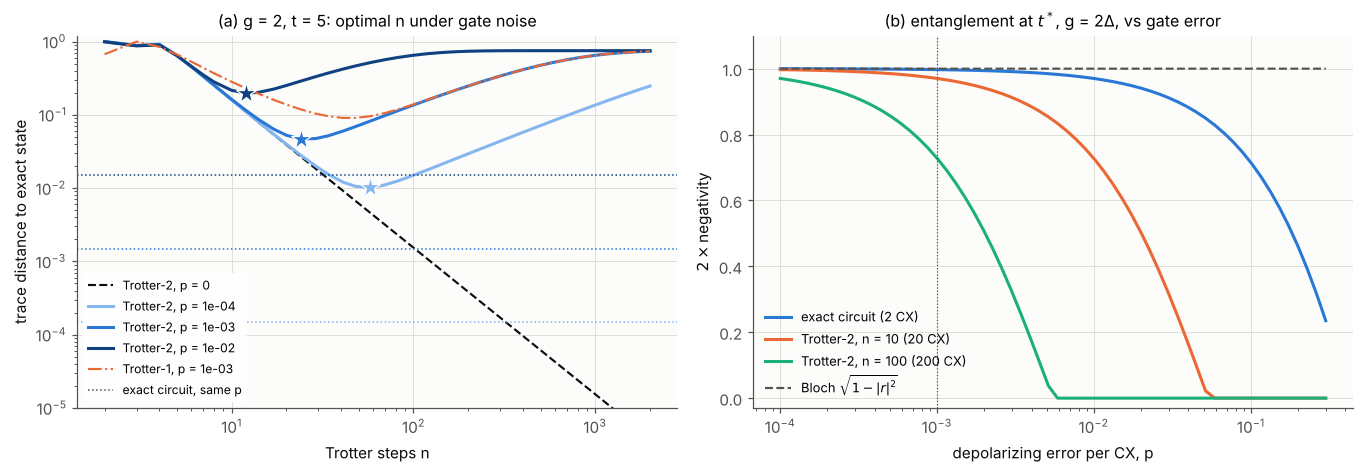

In [23]:
P_GRID = np.geomspace(1e-4, 0.3, 60)
depths = [("exact circuit (2 CX)", None), ("Trotter-2, n = 10 (20 CX)", 10), ("Trotter-2, n = 100 (200 CX)", 100)]
ent_noise = {}
for label, n in depths:
    rhos = [noisy_exact_rho(2.0, t_star, p) if n is None else noisy_trotter_rho(2.0, t_star, n, 2, p) for p in P_GRID]
    ent_noise[label] = dict(N2=np.array([2 * negativity(r) for r in rhos]),
                            bloch=np.array([bloch_estimator(r) for r in rhos]))
p_lost = {label: float(P_GRID[np.argmax(v["N2"] <= 1e-12)]) if np.any(v["N2"] <= 1e-12) else None
          for label, v in ent_noise.items()}
at_1e3 = {label: float(np.interp(np.log(1e-3), np.log(P_GRID), v["N2"])) for label, v in ent_noise.items()}
print("2 x negativity at g = 2, t* with p = 1e-3 per CX:")
for label in at_1e3:
    print(f"  {label:28s} {at_1e3[label]:.3f}   entanglement gone for p >= {p_lost[label]:.2e}" if p_lost[label]
          else f"  {label:28s} {at_1e3[label]:.3f}")
print(f"spin-only Bloch estimator over the whole p grid: {min(v['bloch'].min() for v in ent_noise.values()):.3f} "
      f"to {max(v['bloch'].max() for v in ent_noise.values()):.3f}")
write_csv("noise_entanglement.csv", ["circuit", "p", "2N", "C_bloch"],
          [[label, p, a, b] for label, v in ent_noise.items() for p, a, b in zip(P_GRID, v["N2"], v["bloch"])])

RAMP = {1e-4: "#86b6ef", 1e-3: "#2a78d6", 1e-2: "#104281"}
fig, (e1, e2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
e1.loglog(N_STEPS, curves[(2, 0.0)], color=INK, lw=1.4, ls="--", label="Trotter-2, p = 0")
for p, col in RAMP.items():
    e1.loglog(N_STEPS, curves[(2, p)], color=col, lw=2, label=f"Trotter-2, p = {p:.0e}")
    k = int(np.argmin(curves[(2, p)]))
    e1.plot(N_STEPS[k], curves[(2, p)][k], "*", color=col, ms=14, mec="white", mew=0.8, zorder=5)
    e1.axhline(exact_err[p], color=col, lw=1, ls=":")
e1.loglog(N_STEPS, curves[(1, 1e-3)], color=C2, lw=1.4, ls="-.", label="Trotter-1, p = 1e-03")
e1.plot([], [], color=INK2, lw=1, ls=":", label="exact circuit, same p")
e1.set(xlabel="Trotter steps n", ylabel="trace distance to exact state",
       title=f"(a) g = {G_NOISE:g}, t = {T_NOISE:g}: optimal n under gate noise", ylim=(1e-5, 1.2))
e1.legend(loc="lower left", fontsize=8, frameon=True, facecolor="white", edgecolor="none", framealpha=0.92)
for (label, v), col in zip(ent_noise.items(), [C1, C2, C3]):
    e2.semilogx(P_GRID, v["N2"], color=col, lw=2, label=label)
e2.semilogx(P_GRID, ent_noise[depths[1][0]]["bloch"], color=INK2, lw=1.4, ls="--", label=r"Bloch $\sqrt{1-|r|^2}$")
e2.axvline(1e-3, color=INK2, lw=0.8, ls=":")
e2.set(xlabel="depolarizing error per CX, p", ylabel=r"$2\times$negativity", ylim=(-0.03, 1.1),
       title=r"(b) entanglement at $t^*$, g = 2Δ, vs gate error")
e2.legend(loc="lower left", fontsize=8.5)
fig.tight_layout()
save(fig, "F9_gate_noise")

## 11. Robustness of the modelling choices (F10)

(a) Initial spin state at $g = 2$: relative phase of the equal superposition, a polarized spin, and a classical 50/50 mixture. (b) $\Delta \neq 1$: $P_R$ against $\Delta t$ at fixed $g/2\Delta$.

g = 2: initial spin      max|dP_R|   max 2N
       φ = 0               0.0e+00    1.000
       φ = π/4             1.7e-16    1.000
       φ = π/2             5.6e-17    1.000
       φ = π               5.6e-17    1.000
       φ = 3π/2            5.6e-17    1.000
       spin ↑              3.9e-16    0.000
       spin ↓              3.3e-16    0.000
       50/50 mixture       3.3e-16    0.000
P_R(Δt) at fixed g/2Δ, Δ = (0.6, 1.0, 2.5): max deviation from Δ = 1 is 1.8e-15


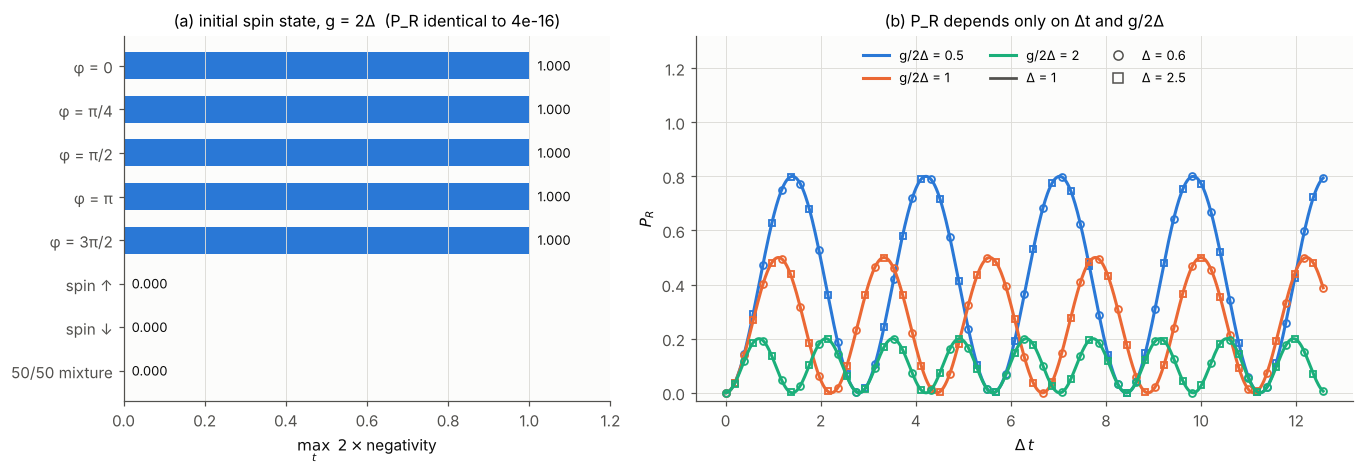

In [24]:
def trajectory_from(psi0, g, times, delta=DELTA):
    evals, vecs = np.linalg.eigh(hamiltonian(g, delta).to_matrix())
    c0 = vecs.conj().T @ psi0
    return (np.exp(-1j * np.outer(np.asarray(times), evals)) * c0) @ vecs.T


def spin_state(a_up, a_down):
    v = np.zeros(4, dtype=complex)
    v[0], v[2] = a_up, a_down
    return v / np.linalg.norm(v)


def max_N2(traj_list, weights):
    out = 0.0
    for k in range(0, len(TS), 10):
        rho = sum(w * np.outer(s[k], s[k].conj()) for s, w in zip(traj_list, weights))
        out = max(out, 2 * negativity(rho))
    return out


g_r = 2.0
ref = p_right_many(exact_trajectory(g_r, TS))
cases = [(f"φ = {name}", [spin_state(1, np.exp(1j * ph))], [1.0])
         for name, ph in (("0", 0.0), ("π/4", np.pi / 4), ("π/2", np.pi / 2), ("π", np.pi), ("3π/2", 3 * np.pi / 2))]
cases += [("spin ↑", [spin_state(1, 0)], [1.0]), ("spin ↓", [spin_state(0, 1)], [1.0]),
          ("50/50 mixture", [spin_state(1, 0), spin_state(0, 1)], [0.5, 0.5])]
init_rows = []
for name, psis, ws in cases:
    trajs = [trajectory_from(s, g_r, TS) for s in psis]
    p_r = sum(w * p_right_many(tr) for tr, w in zip(trajs, ws))
    init_rows.append(dict(initial_spin=name, max_dP_R=float(np.max(np.abs(p_r - ref))), max_2N=max_N2(trajs, ws)))
print(f"g = {g_r:g}: {'initial spin':16s} {'max|dP_R|':>10} {'max 2N':>8}")
for r in init_rows:
    print(f"       {r['initial_spin']:16s} {r['max_dP_R']:10.1e} {r['max_2N']:8.3f}")
assert max(r["max_dP_R"] for r in init_rows) < 1e-12
write_csv("initial_state_check.csv", list(init_rows[0]), [list(r.values()) for r in init_rows])

DELTAS, RATIOS = (0.6, 1.0, 2.5), (0.5, 1.0, 2.0)
x_dt = np.linspace(0, 4 * np.pi, 801)
scal, scal_dev = {}, 0.0
for ratio in RATIOS:
    for d in DELTAS:
        scal[(ratio, d)] = p_right_many(exact_trajectory(2 * ratio * d, x_dt / d, delta=d))
    scal_dev = max(scal_dev, max(np.max(np.abs(scal[(ratio, d)] - scal[(ratio, 1.0)])) for d in DELTAS))
print(f"P_R(Δt) at fixed g/2Δ, Δ = {DELTAS}: max deviation from Δ = 1 is {scal_dev:.1e}")
assert scal_dev < 1e-12
write_csv("delta_scaling.csv", ["g_over_2Delta", "Delta", "Delta_t", "P_R"],
          [[ratio, d, x, p] for (ratio, d), ps in scal.items() for x, p in zip(x_dt[::10], ps[::10])])

fig, (f1, f2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw=dict(width_ratios=[1, 1.35]))
names = [r["initial_spin"] for r in init_rows]
vals = [r["max_2N"] for r in init_rows]
cols = [C1 if n.startswith("φ") else INK2 for n in names]
f1.barh(range(len(names)), vals, color=cols, height=0.62)
for i, v in enumerate(vals):
    f1.text(v + 0.02, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
f1.set_yticks(range(len(names)), names)
f1.invert_yaxis()
f1.set(xlim=(0, 1.2), xlabel=r"$\max_t\ 2\times$negativity",
       title=f"(a) initial spin state, g = 2Δ  (P_R identical to {max(r['max_dP_R'] for r in init_rows):.0e})")
f1.grid(axis="y", visible=False)
for ratio, col in zip(RATIOS, [C1, C2, C3]):
    f2.plot(x_dt, scal[(ratio, 1.0)], color=col, lw=2, label=f"g/2Δ = {ratio:g}")
    for d, mk, k0 in ((0.6, "o", 0), (2.5, "s", 12)):
        f2.plot(x_dt[k0::25], scal[(ratio, d)][k0::25], mk, color=col, ms=4.5, mfc="none", mew=1.2)
f2.plot([], [], "-", color=INK2, label="Δ = 1")
f2.plot([], [], "o", color=INK2, mfc="none", label="Δ = 0.6")
f2.plot([], [], "s", color=INK2, mfc="none", label="Δ = 2.5")
f2.set(xlabel=r"$\Delta\,t$", ylabel=r"$P_R$", ylim=(-0.03, 1.32), title="(b) P_R depends only on Δt and g/2Δ")
f2.legend(loc="upper center", ncol=3, fontsize=8.5)
fig.tight_layout()
save(fig, "F10_robustness")

## 12. Captions, summary and reproducibility record

In [25]:
n9 = {r["p"]: r for r in noise_rows}
CAPTIONS_EXT = {
    "F9_gate_noise":
        f"Gate noise (density matrix; two-qubit depolarizing error p after every CX; g = 2). (a) Trace distance to the exact "
        f"state at t = {T_NOISE:g} vs number of Trotter-2 steps; stars mark the optimum (n = {n9[1e-3]['n_opt_T2']} at p = 1e-3, "
        f"distance {n9[1e-3]['D_min_T2']:.3f}); dotted lines: exact 2-CX circuit under the same noise ({exact_err[1e-3]:.1e} at p = 1e-3); "
        f"dash-dot: Trotter-1 at p = 1e-3. (b) 2×negativity at t* vs p for circuits with 2, 20 and 200 CX; dashed: spin-only "
        f"Bloch estimator, which stays near 1 while the entanglement is lost.",
    "F10_robustness":
        f"(a) Maximum 2×negativity at g = 2Δ for different initial spin states (SV). All give the same P_R(t) "
        f"(max deviation {max(r['max_dP_R'] for r in init_rows):.0e}); only spin superpositions become entangled, independent of their relative phase. "
        f"(b) P_R against Δt for Δ = 0.5, 1, 2 at fixed g/2Δ (SV); curves coincide to {scal_dev:.0e}.",
}
with open(FIG / "CAPTIONS.md", "a", encoding="utf-8") as f:
    for k, v in CAPTIONS_EXT.items():
        f.write(f"**{k}**: {v}\n\n")

SUMMARY["gate_noise"] = dict(g=G_NOISE, t=T_NOISE, optimal_steps=noise_rows, exact_circuit_error=exact_err,
                             N2_at_p1e3=at_1e3, p_entanglement_lost=p_lost)
SUMMARY["robustness"] = dict(initial_states=init_rows, delta_scaling_max_dev=scal_dev)
SUMMARY["runtime_s"] = round(time.time() - T0, 1)
write_json("summary.json", SUMMARY)
print(f"p = 1e-3: exact circuit error {exact_err[1e-3]:.1e}; best Trotter-2 error {n9[1e-3]['D_min_T2']:.3f} at n = {n9[1e-3]['n_opt_T2']}")
print(f"p = 1e-3: 2N at t* = {at_1e3[depths[0][0]]:.3f} (exact circuit), {at_1e3[depths[2][0]]:.3f} (Trotter-2, n = 100)")

p = 1e-3: exact circuit error 1.5e-03; best Trotter-2 error 0.047 at n = 24
p = 1e-3: 2N at t* = 0.997 (exact circuit), 0.728 (Trotter-2, n = 100)


In [26]:
import hashlib, platform, sys
import scipy, matplotlib

files = sorted(p for p in list(FIG.glob("*")) + list(DATA.glob("*")) if p.name != "manifest.json")
manifest = dict(python=sys.version.split()[0], platform=platform.platform(),
                packages={"qiskit": qiskit.__version__, "numpy": np.__version__,
                          "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
                seeds=SUMMARY["seeds"], runtime_s=round(time.time() - T0, 1),
                sha256={p.as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in files})
write_json("manifest.json", manifest)
print(f"python {manifest['python']} | " + " | ".join(f"{k} {v}" for k, v in manifest["packages"].items()))
print(f"{len(files)} output files hashed into data/manifest.json; total runtime {manifest['runtime_s']} s")

python 3.13.16 | qiskit 2.5.2 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2
40 output files hashed into data/manifest.json; total runtime 54.5 s
